# Glyco Atlas: charting diabetes as a knowledge graph

This notebook walks through the whole `graph_01` project from the first idea to the last check: what problem a knowledge graph solves, where the articles came from, how plain Vietnamese health text became clean facts, how those facts live in Neo4j, how we question them, how we draw them, and how far we can trust them. Every step comes with the **reason** behind it, and with what would go wrong if it were done differently.

The project is four programs that run one after the other, and each reads what the previous one wrote:

```
vinmec.com ─▶ [1] kg/crawl.py    ─▶ dataset/raw/pages/*.json     1,096 articles as structured text
           ─▶ [2] kg/extract.py  ─▶ dataset/processed/*.csv      facts: (subject, relation, object)
           ─▶ [3] kg/load.py     ─▶ Neo4j                        nodes + relationships on disk
           ─▶ [4] Cypher · kg/retriever.py · kg/visualize.py     answers, retrieved facts, figures
```

Why four programs and not one big script? Because each stage is slow or fragile in its own way:

- **Crawling** takes about 20 minutes and needs the website to be reachable, so it is done once and the result is saved.
- **Extraction** is where the rules were tuned (several times, after checking quality), so it has to be cheap to re-run without downloading anything.
- **Loading** is separate so the database can be wiped and rebuilt from the CSV files at any moment.

This notebook re-implements none of them. It imports their functions and opens each stage so you can look at the data in between.

| Part | What you will see |
|---|---|
| 1 | Facts as arrows: a graph built by hand from 7 diabetes facts |
| 2 | The articles: how pages were found, why many were rejected, what a saved page looks like |
| 3 | From prose to triples: vocabulary, section rules, choosing the subject, counting evidence |
| 4 | The graph we ended up with |
| 5 | Moving into Neo4j: why a graph database, how the data is modelled and loaded |
| 6 | Asking the graph: one-hop, two-hop, symptom finder, paths, evidence |
| 7 | Bounded retrieval with `graph_facts()` |
| 8 | Seeing the graph, and finding what matters in it |
| 9 | How far to trust it |
| 10 | Blind spots |

**Before running:** Neo4j must be up (`docker compose up -d neo4j`) and loaded (`docker compose run --rm load`). From Part 5 on, the cells talk to the database.

In [1]:
import sys, json, csv, re
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT / "kg"))

import atlas
import visualize as V
from atlas import ACCENT, INK, INK_FAINT, INK_SOFT, TYPE_COLORS, kv, rule, tbl

atlas.style()
RAW, PROC = ROOT / "dataset" / "raw", ROOT / "dataset" / "processed"

rule("Glyco Atlas · notebook environment")
kv({"project root": ROOT, "raw pages": len(list((RAW / "pages").glob("*.json"))),
    "processed csv": ", ".join(p.name for p in sorted(PROC.glob("*.csv"))), "plot font": atlas.SANS})


━━━ Glyco Atlas · notebook environment ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  project root  │ F:\Code\intelligent_system_assignments\graph_01
  raw pages     │ 1
  processed csv │ articles.csv, entities.csv, mentions.csv, triples.csv
  plot font     │ Segoe UI


## 1 · Facts as arrows

### Text is hard for a program

Vinmec's page on type 2 diabetes says, among many other things:

> *"Những triệu chứng kinh điển của tiểu đường: ăn nhiều, uống nhiều, tiểu nhiều, gầy nhiều… Biến chứng mạn tính: nhìn mờ do biến chứng võng mạc… tê bì dị cảm ở bàn chân (biến chứng thần kinh)…"*

A person reads this and understands it at once. A program sees a long string of characters. Ask it *"which complications of type 2 diabetes affect the eyes?"* and all it can do is search for words, and word search is unreliable:

- the word "mắt" (eye) may not appear at all, because the text says "võng mạc" (retina);
- it may appear in a sentence that says the opposite of what you want;
- the answer is usually spread over many articles, each written differently.

### The idea: store small facts instead of sentences

A knowledge graph stores knowledge as many small, separate **facts**. Each fact joins exactly two things with a named relationship, always in the same three-part shape: *(the thing the fact is about, the kind of relationship, the other thing)*. That shape is a **triple**; its parts are the **subject**, the **relation** and the **object**.

The paragraph above turns into facts such as:

| subject | relation | object |
|---|---|---|
| Đái tháo đường type 2 | HAS_SYMPTOM | Khát nhiều |
| Đái tháo đường type 2 | HAS_SYMPTOM | Tiểu nhiều |
| Đái tháo đường type 2 | HAS_COMPLICATION | Bệnh võng mạc |
| Bệnh võng mạc | AFFECTS_ORGAN | Mắt |

Why is that better?

- Every fact has a **fixed, predictable form**. A program does not need Vietnamese grammar; it looks for subject "type 2" and relation `HAS_COMPLICATION`.
- The ambiguity of language is removed **once**, when the fact is created, instead of every time someone asks a question.

### Why it is called a graph

Draw every thing as a dot and every fact as an arrow between two dots, and you get a network. The things are **nodes** (entities); the facts are **edges** (relationships). Each node also has a **type** (`Symptom`, `Drug`, `Complication`…) so the program knows what kind of thing it is.

The network view is what makes it powerful, because questions turn into **walks along arrows**. To answer "which organs can type 2 diabetes damage?", start at *type 2*, follow every `HAS_COMPLICATION` arrow, then follow each complication's `AFFECTS_ORGAN` arrow. No single fact holds the answer; two steps combine facts into new knowledge. And since you can list the arrows you walked, the answer explains itself, which a neural network that predicts an answer cannot do.

Let us build a tiny version by hand, as the lecture does, before meeting the real graph with 339 facts.


━━━ the toy graph ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  nodes │ 8
  edges │ 7


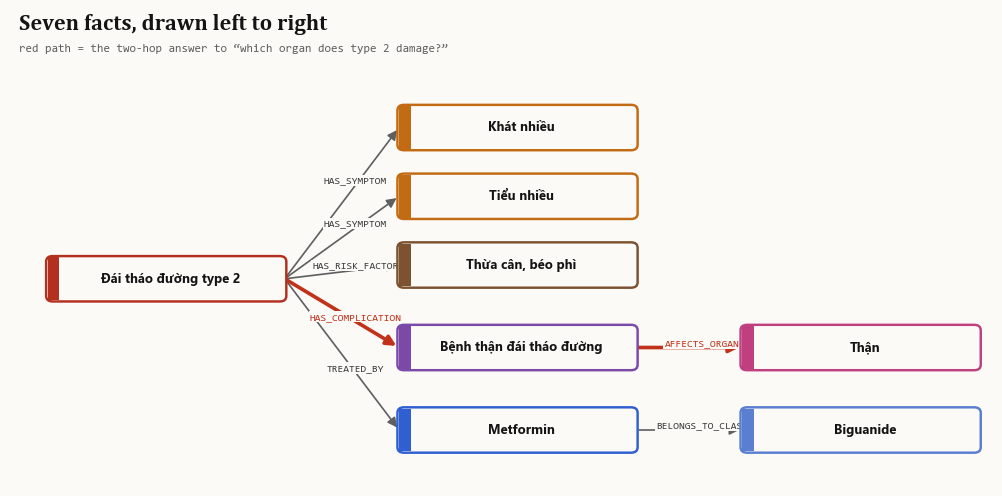

In [2]:
toy = [
    ("Đái tháo đường type 2", "HAS_SYMPTOM",      "Khát nhiều"),
    ("Đái tháo đường type 2", "HAS_SYMPTOM",      "Tiểu nhiều"),
    ("Đái tháo đường type 2", "HAS_RISK_FACTOR",  "Thừa cân, béo phì"),
    ("Đái tháo đường type 2", "HAS_COMPLICATION", "Bệnh thận đái tháo đường"),
    ("Đái tháo đường type 2", "TREATED_BY",       "Metformin"),
    ("Bệnh thận đái tháo đường", "AFFECTS_ORGAN", "Thận"),
    ("Metformin", "BELONGS_TO_CLASS", "Biguanide"),
]
T = nx.DiGraph()
for s, r, o in toy:
    T.add_edge(s, o, relation=r)

rule("the toy graph")
kv({"nodes": T.number_of_nodes(), "edges": T.number_of_edges()})
V.draw_toy()
plt.show()

### One hop and two hops

There are two basic kinds of question.

- A **one-hop** question reads only the arrows touching one node. "What do we know about Metformin?" means: find the Metformin dot and read every arrow on it, both leaving it (Metformin → Biguanide) and arriving at it (type 2 → Metformin). The direction only says how the fact is *phrased*; for "what do we know about X" we want both.
- A **two-hop** question chains two arrows through a node in the middle. "Which organ does type 2 damage?" cannot be answered by one arrow, because no article states "type 2 damages the kidney" as a single fact. The article says type 2 can cause *diabetic kidney disease*, and we separately know that this disease affects the *kidney*. The middle node, the complication, is the bridge.

That bridge is exactly where a graph beats a pile of sentences: combining facts is just following arrows. The helper below turns arrows back into readable lines; Part 7 uses the real version on the real graph.

In [3]:
def arrow(s, r, o):
    return f"{s}  ─[{r}]─▶  {o}"

rule("one hop · everything touching Metformin")
for s, o, d in list(T.out_edges("Metformin", data=True)) + list(T.in_edges("Metformin", data=True)):
    print("  ", arrow(s, d["relation"], o))

rule("two hops · organs damaged by type 2")
for _, comp, d1 in T.out_edges("Đái tháo đường type 2", data=True):
    if d1["relation"] != "HAS_COMPLICATION":
        continue
    for _, organ, d2 in T.out_edges(comp, data=True):
        if d2["relation"] == "AFFECTS_ORGAN":
            print(f"   type 2  ═▶  {comp}  ═▶  {organ}")


━━━ one hop · everything touching Metformin ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
   Metformin  ─[BELONGS_TO_CLASS]─▶  Biguanide
   Đái tháo đường type 2  ─[TREATED_BY]─▶  Metformin

━━━ two hops · organs damaged by type 2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
   type 2  ═▶  Bệnh thận đái tháo đường  ═▶  Thận


The rest of the notebook is the same idea at a larger scale. Building a graph from 7 facts by hand is easy; the hard part of the project is getting **correct facts out of 1,096 Vietnamese articles automatically**, with nobody reading each one. Parts 2 and 3 explain how, and why each decision was made.

## 2 · Gathering the articles

### 2.1 Why Vinmec

Vinmec is a large Vietnamese hospital group. Its website publishes thousands of health articles written or reviewed by its doctors, plus official "disease pages" with a fixed layout (overview, causes, symptoms, risk groups, prevention, diagnosis, treatment). For a Vietnamese diabetes graph this is a good source:

- **the language matches**: the graph uses the words readers actually use;
- **the topic is covered in depth**: almost a thousand diabetes articles;
- **the writing is consistent**: the same headings recur, and that is what makes automatic extraction possible.

### 2.2 Finding the pages

The obvious route is the website's search box, but it does not work for a program. Vinmec builds its search results with JavaScript *after* the page loads, so a program that downloads the search page gets the empty shell and no results.

The crawler therefore uses the **sitemap**, the list of all URLs that large sites publish for search engines:

- Vinmec's sitemap points to about 230 smaller sitemaps;
- the crawler reads the Vietnamese article ones (`posts-vi-*.xml`) and disease-page ones (`diseases-vi-*.xml`), about 222,000 URLs, i.e. the whole Vietnamese site.

To pick diabetes pages out of 222,000 without downloading them all, it reads the **slug**, the short accent-free name at the end of every URL (`tieu-duong-tuyp-2-…`). A page is a candidate if its slug holds a diabetes keyword, and the keywords come in two strengths:

- **strong** (`tieu-duong`, `thao-duong`): the page is almost certainly about diabetes;
- **weak** (`insulin`, `hba1c`, `duong-huyet`, `metformin`): the page *might* be, but these words also appear in articles about other things, such as blood sugar in healthy people or the hormone insulin in general.

The slug `thao-nhat` is excluded on purpose. *Đái tháo nhạt* (diabetes insipidus) shares "đái tháo" with *đái tháo đường* but is a different disease of the kidneys and hormones, not of blood sugar.

The result is **1,197 candidate URLs**. The crawler fetches them politely: `robots.txt` allows these pages, and it waits one second between requests.

### 2.3 Why a second filter is needed

Choosing by slug hides a trap that comes from dropping accents. Vietnamese has many words that differ *only* by accent, and without accents they collapse into one:

- `tieu-duong` is *tiểu đường* (diabetes) but also the start of *tiểu dương vật* (a urology article about a child);
- `dai-duong` is *đái đường* (diabetes) but also *đại dương* (ocean, as in "cá ngừ đại dương");
- `duong` also hides *dưỡng ẩm* (moisturising).

These pages pass the slug test and have nothing to do with diabetes. So after download every page is re-checked on its real text, **with accents**, where the words cannot be confused. Two counts are taken: how often it says *tiểu đường / đái tháo đường / ĐTĐ* (the **diabetes count**) and how often it uses related terms such as *đường huyết, insulin, HbA1c* (the **related count**). A page is kept when:

1. it is an **official Vinmec disease page** (Vinmec already classed it as diabetes); or
2. its **title or summary** mentions diabetes and the text mentions it twice (the title is the strongest signal); or
3. its slug had a **strong** keyword and the text mentions diabetes at least 3 times (accent collisions mention it zero times); or
4. its slug had only a **weak** keyword, and the text has at least 5 diabetes mentions *and* 5 related terms (an article "Insulin là gì?" that names the hormone 30 times but diabetes once is biology, not disease).

The thresholds are loose where the evidence is strong (the title) and strict where a wrong page is likely (a weak keyword).

In [4]:
idx = pd.read_csv(RAW / "index.csv")
rule("relevance filter")
kv({"candidates checked": len(idx), "kept": int(idx.relevant.sum()), "rejected": int((~idx.relevant).sum())})

ct = pd.crosstab(idx.slug_match, idx.relevant, margins=True).rename(columns={True: "kept", False: "rejected", "All": "total"})
tbl(ct.rename_axis("slug keyword").reset_index(), "kept vs rejected, by strength of the slug keyword")

rej = idx[~idx.relevant][["title", "slug_match", "core_mentions", "related_mentions"]].dropna().head(8)
tbl(rej, "a few rejected pages: accent collisions and off-topic", limit=52)


━━━ relevance filter ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  candidates checked │ 1191
  kept               │ 1096
  rejected           │ 95

▎kept vs rejected, by strength of the slug keyword
┌──────────────┬──────────┬──────┬───────┐
│ SLUG KEYWORD │ REJECTED │ KEPT │ TOTAL │
├──────────────┼──────────┼──────┼───────┤
│ strong       │       10 │  934 │   944 │
│ weak         │       85 │  162 │   247 │
│ All          │       95 │ 1096 │  1191 │
└──────────────┴──────────┴──────┴───────┘
  3 rows

▎a few rejected pages: accent collisions and off-topic
┌──────────────────────────────────────────────────────┬────────────┬───────────────┬──────────────────┐
│ TITLE                                                │ SLUG_MATCH │ CORE_MENTIONS │ RELATED_MENTIONS │
├──────────────────────────────────────────────────────┼────────────┼───────────────┼──────────────────┤
│ Trẻ 19 tháng đi tiểu dương vật không cử động cần là… │ strong     │             0 │          

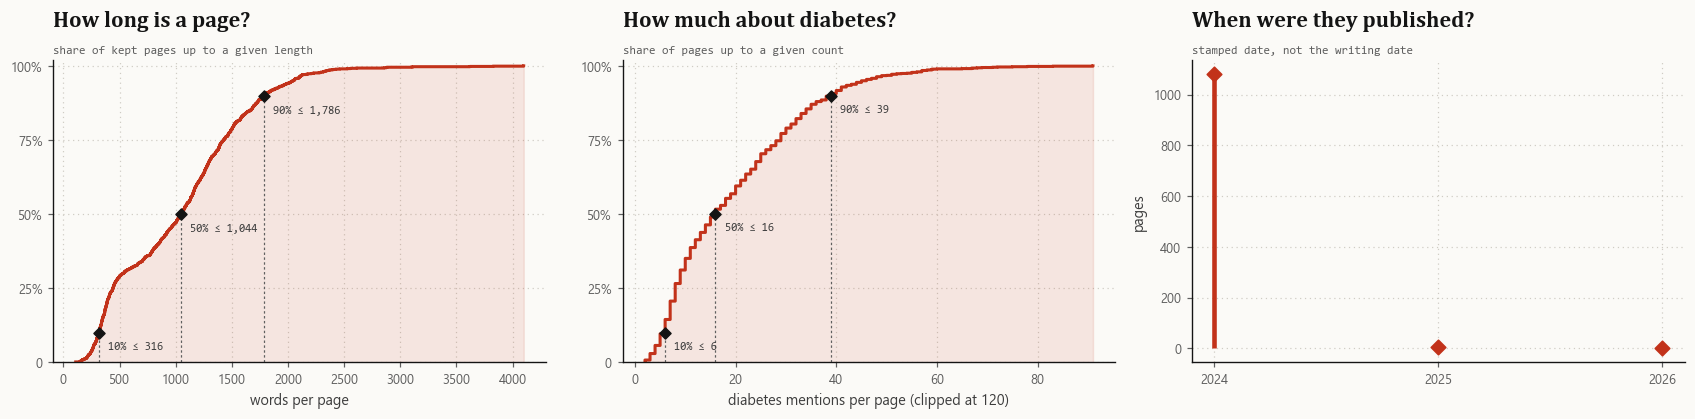


━━━ corpus size ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  kept pages               │ 1096
  words in total           │ 1,130,914
  median page              │ 1044 words
  median diabetes mentions │ 16


In [5]:
kept = idx[idx.relevant]
years = pd.to_datetime(kept.date_published, errors="coerce").dt.year.dropna().astype(int).value_counts().sort_index()

fig, ax = plt.subplots(1, 3, figsize=(15.5, 3.9))
V.ecdf(ax[0], kept.n_words, marks=(.1, .5, .9)); ax[0].set_xlabel("words per page")
atlas.title(ax[0], "How long is a page?", "share of kept pages up to a given length")
V.ecdf(ax[1], kept.core_mentions.clip(upper=120), marks=(.1, .5, .9)); ax[1].set_xlabel("diabetes mentions per page (clipped at 120)")
atlas.title(ax[1], "How much about diabetes?", "share of pages up to a given count")
ax[2].vlines(years.index, 0, years.values, color=ACCENT, lw=3)
ax[2].scatter(years.index, years.values, marker="D", s=46, color=ACCENT, zorder=3)
ax[2].set_xticks(years.index); ax[2].set_ylabel("pages")
atlas.title(ax[2], "When were they published?", "stamped date, not the writing date")
plt.tight_layout(); plt.show()

rule("corpus size")
kv({"kept pages": len(kept), "words in total": f"{kept.n_words.sum():,}", "median page": f"{kept.n_words.median():.0f} words",
    "median diabetes mentions": f"{kept.core_mentions.median():.0f}"})

### 2.4 What one saved page looks like

The crawler does **not** keep raw HTML. HTML is full of menus, advertisements, booking forms, footers and scripts, and the article itself is maybe a quarter of it. Instead the crawler finds the article body and cuts it into **sections**. For each section it saves three things:

- the **heading** it sits under;
- its **paragraphs**;
- its **bullet points**, as separate items.

Keeping the heading is the most important design decision in the project, and Part 3 shows why. The heading says *what kind of information* the text below it holds: the bullet "Mệt mỏi" (fatigue) means one thing under "Triệu chứng" (symptoms) and something else under "Tác dụng phụ của thuốc" (drug side effects). Without the heading we could not tell.

The tail of every article is cut off as well: the booking text ("Để đặt lịch khám tại viện, Quý khách vui lòng bấm số HOTLINE…") and the "Xem thêm:" links. If kept, every article would "mention" the same booking words and the related-article links would drag in words from other topics.

Below is Vinmec's official disease page for type 2 diabetes exactly as it is stored.

In [6]:
page = json.loads((RAW / "pages" / "tieu-duong-tuyp-2-3042.json").read_text(encoding="utf-8"))
rule("one stored page")
kv({"title": page["title"], "url": page["url"], "type": page["page_type"], "sections": len(page["sections"])})
print()
for i, s in enumerate(page["sections"]):
    last = i == len(page["sections"]) - 1
    print(f"  {'└─' if last else '├─'} {s['heading']}   [{len(s['paragraphs'])} ¶ · {len(s['bullets'])} •]")
    for b in s["bullets"][:3]:
        print(f"  {'   ' if last else '│  '}    • {b[:96]}")


━━━ one stored page ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  title    │ Tiểu đường tuýp 2: Nguyên nhân, triệu chứng, chẩn đoán và điều trị
  url      │ https://www.vinmec.com/vie/benh/tieu-duong-tuyp-2-3042
  type     │ disease
  sections │ 9

  ├─ Tổng quan bệnh Tiểu đường tuýp 2   [4 ¶ · 0 •]
  ├─ Nguyên nhân bệnh Tiểu đường tuýp 2   [1 ¶ · 0 •]
  ├─ Triệu chứng bệnh Tiểu đường tuýp 2   [3 ¶ · 4 •]
  │      • Ăn nhiều
  │      • Uống nhiều (hay khát nước)
  │      • Tiểu nhiều (do đường trong nước tiểu cao, gây lợi niệu thẩm thấu)
  ├─ Biến chứng cấp tính   [1 ¶ · 0 •]
  ├─ Biến chứng mạn tính   [0 ¶ · 6 •]
  │      • Nhìn mờ (do biến chứng võng mạc, đục thủy tinh thể)
  │      • Đau ngực thường không điển hình (do biến chứng mạch vành)
  │      • Tê bì dị cảm ở bàn chân (biến chứng thần kinh)
  ├─ Đối tượng nguy cơ bệnh Tiểu đường tuýp 2   [0 ¶ · 8 •]
  │      • Béo phì: tình trạng thừa cân làm tăng sự đề kháng insulin
  │      • Lối sống tĩnh tại: ít 

## 3 · From prose to triples

This is the heart of the project: `kg/extract.py`. It reads 1,096 articles and writes facts of the form (subject, relation, object), without a human reading the articles.

### Why not make every bullet a node?

The simplest idea: take every bullet under "Triệu chứng" and make it a Symptom node. On the type 2 page that gives "Ăn nhiều" and "Uống nhiều (hay khát nước)", which looks fine. But here is a bullet under "điều trị" on the type 1 page:

> *"Kiểm soát đường huyết: đối với tuýp 1 thì kiểm soát bằng insulin ngoại sinh là chủ yếu. Dùng theo phác đồ, tuân thủ giờ tiêm và liều lượng tránh bị tụt đường huyết. Các loại insulin gồm có…"*

That is 60 words. As a node it is useless:

- no other article will ever write the same 60 words, so it connects to nothing and no question matches it;
- even short bullets differ between articles ("uống nhiều", "khát nước", "hay khát"), so the single fact "diabetes causes thirst" would break into weak pieces that never meet.

So instead of copying text into the graph we decide **in advance** what the graph may contain, give each thing one clean name, and search the text for every way it can be written. That fixed list is the **vocabulary**.

### Extraction in three questions

For every section of every page, the extractor asks:

1. **Which diabetes is this page about?** That becomes the subject (type 1, type 2, gestational, prediabetes, or diabetes in general).
2. **What kind of information may this section hold?** The section heading decides. Under "Triệu chứng" symptoms are allowed; under "Điều trị", drugs.
3. **Which vocabulary entries does the text mention?** Those become the objects.

Each fact found on a page is one **vote** from that page. Votes from all pages are added up, and a fact enters the graph only if enough different pages agree.

### 3.1 The vocabulary (`kg/vocab.py`)

Every entry has three parts: a clean **canonical name** (the future node), a **type**, and a list of **aliases**, the different ways Vietnamese articles really write it:

| canonical name | type | aliases searched for |
|---|---|---|
| Khát nhiều | Symptom | khát nhiều, uống nhiều, khát nước, hay khát, khô miệng |
| Metformin | Drug | metformin, glucophage (a brand name) |
| Bệnh võng mạc | Complication | võng mạc, biến chứng mắt, mù lòa |

Turning many spellings into one node is **entity normalisation**, and it is what makes evidence add up: if one article says "uống nhiều" and another "khát nước", both vote for the same fact *(diabetes, HAS_SYMPTOM, Khát nhiều)* and the graph knows two articles agree.

The list was written by hand from the topics the articles cover: classic symptoms, risk factors on Vinmec's pages, acute and chronic complications, standard tests, the drug names used in Vietnam (including brands such as Diamicron, Januvia, Jardiance), foods and lifestyle advice.

- **Cost:** anything not on the list can never be found.
- **Benefit:** every node in the graph is clean, meaningful and correctly typed.

Part 10 returns to the cost.

In [7]:
import vocab
from extract import PATTERNS, LABEL, subject_of, allowed_labels, about_disease, matches

v = pd.DataFrame([(n, lab, len(al), ", ".join(al[:4])) for n, (lab, al) in vocab.VOCAB.items()],
                 columns=["entity", "type", "aliases", "first aliases"])
rule("vocabulary")
kv({"entities": len(v), "aliases": int(v.aliases.sum()), "aliases per entity": f"{v.aliases.mean():.1f}"})
by_type = v.groupby("type").agg(entities=("entity", "count"), aliases=("aliases", "sum")).sort_values("entities", ascending=False)
tbl(by_type, "entries per type", index=True)
tbl(v.sample(7, random_state=1), "a random sample of entries", limit=58)


━━━ vocabulary ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  entities           │ 106
  aliases            │ 320
  aliases per entity │ 3.0

▎entries per type
┌──────────────┬──────────┬─────────┐
│ TYPE         │ ENTITIES │ ALIASES │
├──────────────┼──────────┼─────────┤
│ Drug         │       22 │      42 │
│ Complication │       19 │      52 │
│ RiskFactor   │       17 │      52 │
│ Food         │       16 │      66 │
│ Symptom      │       16 │      56 │
│ Test         │       10 │      35 │
│ Lifestyle    │        6 │      17 │
└──────────────┴──────────┴─────────┘
  7 rows

▎a random sample of entries
┌────────────────────────┬──────────────┬─────────┬────────────────────────────────────────────────────────────┐
│ ENTITY                 │ TYPE         │ ALIASES │ FIRST ALIASES                                              │
├────────────────────────┼──────────────┼─────────┼────────────────────────────────────────────────────────────┤
│ Insulin lispr

### 3.2 How an alias is found in the text

All aliases of an entry are combined into one search pattern (a *regular expression*). Three details matter.

- **A whole word, not part of a longer word.** Vietnamese puts spaces between syllables, so many aliases are one short syllable that also sits inside other words. Unprotected, the fruit alias *lê* (pear) would fire inside *lên* ("lên cân", gaining weight) and *bia* (beer) inside *biên*. The pattern demands that the characters before and after the alias are not letters.
- **Longest alias first.** "Tiểu nhiều" has both "đi tiểu thường xuyên" and the shorter "tiểu thường xuyên". If the short one were tried first, the more precise wording would never be used.
- **Accents are kept.** Text is lower-cased so "HbA1C" and "hba1c" are the same, but accents are never removed, because that would bring back the *tiểu đường* / *tiểu dương* collision from the URLs.

What this does **not** solve: an alias that is itself a whole word with a second meaning. The fruit *táo* (apple) is a complete word inside *táo bón* (constipation), so word boundaries cannot stop it; the last line of the demo shows the false match. The protection is the next rule (3.3): a food alias only counts inside diet sections, and constipation is rarely discussed under "what to eat". The problem is reduced, not removed, and it is listed in Part 10.

Here is the matcher on a real sentence from the type 1 page.

In [8]:
sentence = "Đường huyết lúc đói (nhịn ăn >8-14h) >7 mmol trong 2 buổi sáng khác nhau; HbA1C >6,5%, kèm uống nhiều, tiểu nhiều."
rule("matching a real sentence")
print(f"  “{sentence}”\n")
for lab in ["Test", "Symptom", "Drug"]:
    print(f"  {lab:<8} ▸ {matches(sentence, {lab}) or '—'}")

rule("whole-word demo (Food aliases)")
rows = [(t, matches(t, {"Food"})) for t in ["bệnh nhân lên cân", "ăn quả lê", "uống bia", "bị táo bón kéo dài"]]
tbl(pd.DataFrame(rows, columns=["text", "foods found"]), note="the last row is the known false match")


━━━ matching a real sentence ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  “Đường huyết lúc đói (nhịn ăn >8-14h) >7 mmol trong 2 buổi sáng khác nhau; HbA1C >6,5%, kèm uống nhiều, tiểu nhiều.”

  Test     ▸ ['HbA1c', 'Đường huyết lúc đói']
  Symptom  ▸ ['Khát nhiều', 'Tiểu nhiều']
  Drug     ▸ —

━━━ whole-word demo (Food aliases) ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
┌────────────────────┬──────────────────┐
│ TEXT               │ FOODS FOUND      │
├────────────────────┼──────────────────┤
│ bệnh nhân lên cân  │                  │
│ ăn quả lê          │ Trái cây ít ngọt │
│ uống bia           │ Rượu bia         │
│ bị táo bón kéo dài │ Trái cây ít ngọt │
└────────────────────┴──────────────────┘
  4 rows  ·  the last row is the known false match


### 3.3 The section rule: the heading decides what may be extracted

Finding a vocabulary word in an article does not mean the article *states a fact* about it. Real examples from the corpus:

- *mệt mỏi* (fatigue) appears in a diet article, "ăn sáng đầy đủ giúp bạn đỡ mệt mỏi". That does not make fatigue a symptom of diabetes there.
- *tăng huyết áp* (high blood pressure) appears in drug paragraphs as a condition the drug should not be combined with.
- Nearly every article names *insulin* while explaining how blood sugar works, not because insulin is the treatment under discussion.

Accept every match and the graph would claim dozens of "symptoms" that are merely words that happened to appear. So a match counts only when the **section heading** says the section is about that kind of information. Hospital articles are organised by exactly such headings, so the structure of the article tells us what the bullets mean.

| the heading contains words like | we may extract | which gives the relation |
|---|---|---|
| triệu chứng, dấu hiệu, biểu hiện, nhận biết | symptoms | HAS_SYMPTOM |
| nguyên nhân, nguy cơ, đối tượng, yếu tố, ai dễ | risk factors | HAS_RISK_FACTOR |
| biến chứng, nguy hiểm, hậu quả, ảnh hưởng | complications | HAS_COMPLICATION |
| chẩn đoán, xét nghiệm, chỉ số, kiểm tra, theo dõi | tests | DIAGNOSED_BY |
| điều trị, thuốc, insulin, kiểm soát | drugs and lifestyle measures | TREATED_BY, MANAGED_BY |
| phòng ngừa, lối sống, lưu ý | lifestyle measures | MANAGED_BY |
| ăn, thực phẩm, dinh dưỡng, thực đơn, kiêng | foods | RECOMMENDS_FOOD / AVOIDS_FOOD |

A section with none of these words (for example "Tổng quan", the overview) produces **no facts**. That is on purpose: overviews mention everything briefly, and we would rather miss a fact than invent one.

**An extra check for symptoms and risk factors.** The first version of the rule had a weakness that the quality check in Part 9 exposed. A heading can contain "nguyên nhân" or "nguy cơ" and still not be about diabetes itself:

- *"Một số nguyên nhân gây ngứa bàn tay và bàn chân"* lists causes of **itching**;
- *"Yếu tố nguy cơ gây tai biến mạch máu não ở người tiểu đường"* lists risk factors for a **stroke** in people who already have diabetes;
- *"Làm gì để giảm thiểu nguy cơ tim mạch…"* is advice on **reducing** heart risk.

Reading those bullets as risk factors *of diabetes* produced wrong facts ("high cholesterol is a risk factor of diabetes", when the article meant of the kidney complication). The cause: a symptom or risk factor always belongs to *something*, and the heading names that something. So for symptoms and risk factors only, the heading must also pass `about_disease()`:

- it must name diabetes (tiểu đường, đái tháo đường, tuýp, type, bệnh…) **or** be short and generic ("Triệu chứng", "Ai dễ bị?"), where nothing else is possible; **and**
- it must **not** name another topic (biến chứng, thận, mắt, thần kinh, tim mạch, ngứa, tai biến, hôn mê…); **and**
- it must not be about reducing a risk.

In [9]:
headings = [
    "Triệu chứng bệnh Tiểu đường tuýp 2",
    "Đối tượng nguy cơ bệnh Tiểu đường tuýp 1",
    "3. Ai dễ bị tiền tiểu đường?",
    "Các biện pháp điều trị bệnh Tiểu đường tuýp 1",
    "2.2. Một số thực phẩm mẹ bầu mắc bệnh tiểu đường thai kỳ cần tránh",
    "3. Một số nguyên nhân gây ngứa bàn tay và bàn chân",
    "2. Yếu tố nguy cơ gây tai biến mạch máu não ở người tiểu đường",
    "4. Làm gì để giảm thiểu nguy cơ tim mạch ở bệnh nhân tiểu đường?",
    "Biến chứng mạn tính",
]
tbl(pd.DataFrame([(h, "✔" if about_disease(h) else "✘", ", ".join(sorted(allowed_labels(h))) or "—") for h in headings],
                 columns=["section heading", "about diabetes?", "allowed types"]),
    "the section rule on real headings", limit=66)


▎the section rule on real headings
┌────────────────────────────────────────────────────────────────────┬─────────────────┬─────────────────┐
│ SECTION HEADING                                                    │ ABOUT DIABETES? │ ALLOWED TYPES   │
├────────────────────────────────────────────────────────────────────┼─────────────────┼─────────────────┤
│ Triệu chứng bệnh Tiểu đường tuýp 2                                 │ ✔               │ Symptom         │
│ Đối tượng nguy cơ bệnh Tiểu đường tuýp 1                           │ ✔               │ RiskFactor      │
│ 3. Ai dễ bị tiền tiểu đường?                                       │ ✔               │ RiskFactor      │
│ Các biện pháp điều trị bệnh Tiểu đường tuýp 1                      │ ✔               │ Drug, Lifestyle │
│ 2.2. Một số thực phẩm mẹ bầu mắc bệnh tiểu đường thai kỳ cần tránh │ ✔               │ Food            │
│ 3. Một số nguyên nhân gây ngứa bàn tay và bàn chân                 │ ✘               │ —               │
│

### 3.4 Which diabetes is the subject?

Diabetes is not one disease, and the differences matter:

- **Type 1** is autoimmune: the body destroys its own insulin-producing cells, usually from childhood.
- **Type 2** develops slowly in adults and is tied to weight and lifestyle.
- **Gestational** diabetes appears in pregnancy and usually fades after birth.
- **Prediabetes** is the stage before type 2.

Symptoms, causes and treatments overlap but are not identical: "autoimmune destruction of beta cells" is a cause of type 1 only; "pre-eclampsia" is a complication of gestational diabetes only. Attach every fact to one "diabetes" node and these differences vanish.

So each page gets a subject from its **title**, the author's own short statement of what the article is about. It is far more reliable than counting words in the body (a type 2 article often mentions type 1 for comparison). The first match wins:

| the title contains | subject |
|---|---|
| tuýp 1 / type 1 / típ 1 | Đái tháo đường type 1 |
| tuýp 2 / type 2 / típ 2 | Đái tháo đường type 2 |
| thai kỳ / mang thai / mẹ bầu | Đái tháo đường thai kỳ |
| tiền đái tháo đường / tiền tiểu đường | Tiền đái tháo đường |
| none of these | Đái tháo đường (in general) |

This is a simplification with a visible side effect: most titles name no type ("12 lời khuyên về lối sống để tránh biến chứng tiểu đường"), so the general node collects most facts even though many of those articles are really about type 2. We accept it because a wrong type is worse than a general one: a type 2 fact on the general node is **incomplete**; on the type 1 node it would be **false**.


▎subject_of() on four titles
┌────────────────────────┬────────────────────────────────────────────────────────────────┐
│ SUBJECT                │ TITLE                                                          │
├────────────────────────┼────────────────────────────────────────────────────────────────┤
│ Đái tháo đường type 2  │ Tiểu đường tuýp 2: Nguyên nhân, triệu chứng, chẩn đoán và điề… │
│ Đái tháo đường thai kỳ │ Chế độ ăn cho người bị tiểu đường thai kỳ                      │
│ Tiền đái tháo đường    │ Nguyên nhân và đối tượng nguy cơ tiền tiểu đường               │
│ Đái tháo đường         │ 12 lời khuyên về lối sống để tránh biến chứng tiểu đường       │
└────────────────────────┴────────────────────────────────────────────────────────────────┘
  4 rows


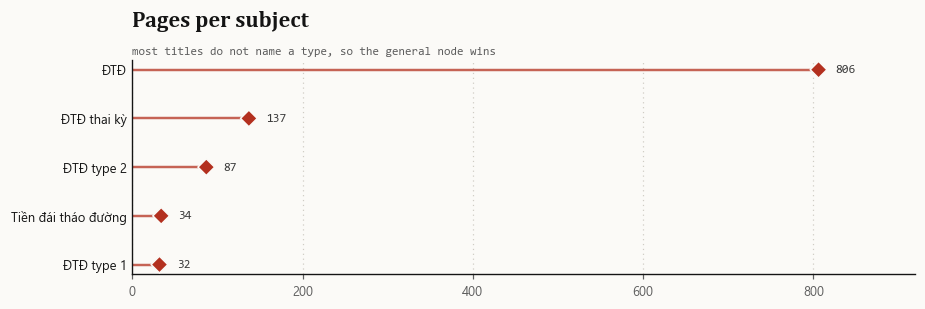

In [10]:
arts = pd.read_csv(PROC / "articles.csv")
tbl(pd.DataFrame([(subject_of(t), t) for t in [
    "Tiểu đường tuýp 2: Nguyên nhân, triệu chứng, chẩn đoán và điều trị",
    "Chế độ ăn cho người bị tiểu đường thai kỳ",
    "Nguyên nhân và đối tượng nguy cơ tiền tiểu đường",
    "12 lời khuyên về lối sống để tránh biến chứng tiểu đường"]], columns=["subject", "title"]), "subject_of() on four titles", limit=62)

counts = arts.about.value_counts()
fig, ax = plt.subplots(figsize=(8.5, 2.9))
V.lollipop(ax, [c.replace("Đái tháo đường", "ĐTĐ") for c in counts.index], counts.values, colors=[TYPE_COLORS["DiabetesType"]] * len(counts))
atlas.title(ax, "Pages per subject", "most titles do not name a type, so the general node wins")
plt.tight_layout(); plt.show()

### 3.5 Walking through one page

Now the three steps together on the type 2 disease page: for each section, which types are allowed and which facts the page votes for. Three things to look for in the output:

- the overview ("Tổng quan") contributes nothing, because its heading has no keyword;
- the symptom section yields exactly the classic symptoms listed on the page;
- the treatment section yields both drugs *and* lifestyle measures, because "điều trị" allows both.

In [11]:
subj = subject_of(page["title"])
rule(f"subject → {subj}")
for s in page["sections"]:
    labels = allowed_labels(s["heading"])
    found = sorted({e for unit in s["paragraphs"] + s["bullets"] for e in matches(unit, labels)})
    print(f"\n  ■ {s['heading']}")
    print(f"      allowed  {', '.join(sorted(labels)) or '— (no keyword, nothing extracted)'}")
    for e in found:
        rel = vocab.RELATION_BY_LABEL.get(LABEL[e], "FOOD")
        print(f"      vote     ▸ {rel:<17} {e}")


━━━ subject → Đái tháo đường type 2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  ■ Tổng quan bệnh Tiểu đường tuýp 2
      allowed  — (no keyword, nothing extracted)

  ■ Nguyên nhân bệnh Tiểu đường tuýp 2
      allowed  RiskFactor
      vote     ▸ HAS_RISK_FACTOR   Di truyền / tiền sử gia đình

  ■ Triệu chứng bệnh Tiểu đường tuýp 2
      allowed  Symptom
      vote     ▸ HAS_SYMPTOM       Khát nhiều
      vote     ▸ HAS_SYMPTOM       Sụt cân
      vote     ▸ HAS_SYMPTOM       Tiểu nhiều
      vote     ▸ HAS_SYMPTOM       Ăn nhiều

  ■ Biến chứng cấp tính
      allowed  Complication
      vote     ▸ HAS_COMPLICATION  Nhiễm toan ceton
      vote     ▸ HAS_COMPLICATION  Tăng áp lực thẩm thấu

  ■ Biến chứng mạn tính
      allowed  Complication
      vote     ▸ HAS_COMPLICATION  Bàn chân đái tháo đường
      vote     ▸ HAS_COMPLICATION  Bệnh thần kinh ngoại biên
      vote     ▸ HAS_COMPLICATION  Bệnh võng mạc
      vote     ▸ HAS_COMPLICATION  Liệt dạ dày
      vote     ▸ HAS

### 3.6 Counting evidence: one page is not enough

Every rule above can still err on a single page: an odd heading, a symptom mentioned in passing, a bullet that lists something for comparison. Trust every page and every such slip becomes a fact.

The defence is **agreement between independent pages**:

- for each fact we keep the *set* of pages that voted for it; a page that says "khát nhiều" five times still counts **once**;
- the size of that set is the fact's **support**;
- a fact enters the graph only when at least **two** pages back it. Same logic as checking a claim against a second source: a stray mention is probably noise, two separately written articles stating the same thing are much more likely right.

Two exceptions, each with its reason:

- facts from an official **disease page** are accepted at support 1, because those pages are short, hospital-reviewed summaries with exactly the standard headings;
- **drug side effects** need support **3**, because they are extracted from single sentences and that is noisier (3.8).

The support number is **kept** after filtering, stored on the fact in Neo4j, so later queries can sort by how well documented an answer is, or demand five agreeing articles.

A worked example with three pages about type 2:

| page | facts it votes for |
|---|---|
| A | type 2 HAS_SYMPTOM Khát nhiều · type 2 HAS_SYMPTOM Mệt mỏi |
| B | type 2 HAS_SYMPTOM Khát nhiều |
| C | type 2 HAS_SYMPTOM Khát nhiều · type 2 HAS_SYMPTOM Run tay |

In [12]:
votes = {"A": [("type 2", "HAS_SYMPTOM", "Khát nhiều"), ("type 2", "HAS_SYMPTOM", "Mệt mỏi")],
         "B": [("type 2", "HAS_SYMPTOM", "Khát nhiều")],
         "C": [("type 2", "HAS_SYMPTOM", "Khát nhiều"), ("type 2", "HAS_SYMPTOM", "Run tay")]}
support = defaultdict(set)
for pg, triples in votes.items():
    for t in triples:
        support[t].add(pg)

rule("counting votes (threshold: 2 pages)")
for t, pages in support.items():
    bar = "■" * len(pages) + "□" * (3 - len(pages))
    print(f"  {t[2]:<11} {bar}  support={len(pages)}  pages={','.join(sorted(pages)):<6} {'✔ kept' if len(pages) >= 2 else '✘ dropped'}")


━━━ counting votes (threshold: 2 pages) ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Khát nhiều  ■■■  support=3  pages=A,B,C  ✔ kept
  Mệt mỏi     ■□□  support=1  pages=A      ✘ dropped
  Run tay     ■□□  support=1  pages=C      ✘ dropped


### 3.7 Foods: recommended or to avoid?

The graph has two food relations, `RECOMMENDS_FOOD` and `AVOIDS_FOOD`. The first version chose between them from the words around the food: "nên ăn" (should eat) meant recommended; "kiêng", "tránh", "hạn chế", "không nên" meant avoid. It failed, and the reason is instructive: diet articles **mix both kinds of advice in the same place**. A heading like *"Thực phẩm mẹ bầu cần tránh và nên ăn"* holds both, and a single sentence says "hạn chế đồ ngọt, thay vào đó nên ăn rau xanh". The output included nonsense such as "gestational diabetes AVOIDS green vegetables".

The final rule treats good-or-bad as a **property of the food**, written once in the vocabulary:

- **avoid:** sweets, soft drinks, white rice and refined starch, very sweet fruit (durian, ripe mango, longan, jackfruit…), alcohol, fried and processed food;
- **recommended:** the rest.

The text then only tells us that the food is **discussed in a diet section** for that type. This matches standard nutrition advice and what the articles say almost always. The cost: nuance ("fruit is fine in moderation") cannot be represented.

### 3.8 Drug side effects

Side effects ignore the section rule because they turn up anywhere: drug sections, complication sections, general articles. They are found **inside one sentence**. A sentence yields a side-effect fact only if it holds:

- a drug, **and**
- a symptom or complication, **and**
- a cue word: *tác dụng phụ* (side effect), *tác dụng không mong muốn* (unwanted effect) or *gây* (causes).

> "Insulin có thể **gây hạ đường huyết** nếu tiêm quá liều" → Insulin HAS_SIDE_EFFECT Hạ đường huyết

One exception: sentences with *thiếu* (lack of) or *không đủ* (not enough) are skipped. "*Thiếu* insulin gây nhiễm toan ceton" has a drug, a complication and "gây", but says a **lack** of insulin causes ketoacidosis, the opposite of a side effect of taking it. Without the exception the graph would warn that insulin causes the very thing it treats.

### 3.9 Background facts added by hand

Some knowledge is not "stated under a heading" but general medical classification that articles take for granted: Metformin is a biguanide, retinopathy affects the eye, the HbA1c threshold is 6.5 %. These are added by hand and labelled `source = "curated"` so they can always be told apart from extracted facts:

- each drug and its **drug class** (Metformin → Biguanide, Empagliflozin → SGLT2 inhibitor…);
- each complication and the **organ** it affects (retinopathy → eye, nephropathy → kidney…);
- each diabetes type as a **subtype** of diabetes in general;
- the diagnostic **thresholds**, stored on the test nodes, from the Vietnamese Ministry of Health 2020 guideline and the American Diabetes Association criteria that Vinmec's pages also quote.

These few facts unlock the most interesting questions. Without "retinopathy affects the eye" the graph could say type 2 causes retinopathy but not answer "which organs does type 2 damage?".

In [13]:
rule("side-effect rule on three sentences")
for s in ["Insulin có thể gây hạ đường huyết nếu tiêm quá liều.",
          "Thiếu insulin gây nhiễm toan ceton.",
          "Metformin là thuốc đầu tay cho tiểu đường tuýp 2."]:
    low = s.lower()
    cue = any(c in low for c in ["tác dụng phụ", "tác dụng không mong muốn", " gây "])
    lack = "thiếu" in low or "không đủ" in low
    drugs, eff = matches(s, {"Drug"}), matches(s, {"Symptom", "Complication"})
    verdict = [(d, "HAS_SIDE_EFFECT", e) for d in drugs for e in eff] if cue and not lack else "no triple"
    print(f"\n  “{s}”")
    print(f"      cue word {'✔' if cue else '✘'}   lack-of-insulin sentence {'✔' if lack else '✘'}   drugs={drugs or '—'}  effects={eff or '—'}")
    print(f"      ▸ {verdict}")


━━━ side-effect rule on three sentences ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  “Insulin có thể gây hạ đường huyết nếu tiêm quá liều.”
      cue word ✔   lack-of-insulin sentence ✘   drugs=['Insulin']  effects=['Hạ đường huyết']
      ▸ [('Insulin', 'HAS_SIDE_EFFECT', 'Hạ đường huyết')]

  “Thiếu insulin gây nhiễm toan ceton.”
      cue word ✔   lack-of-insulin sentence ✔   drugs=['Insulin']  effects=['Nhiễm toan ceton']
      ▸ no triple

  “Metformin là thuốc đầu tay cho tiểu đường tuýp 2.”
      cue word ✘   lack-of-insulin sentence ✘   drugs=['Metformin']  effects=—
      ▸ no triple


## 4 · The graph we ended up with

`extract.py` writes four CSV files, each with one job:

| file | one row is | why it exists |
|---|---|---|
| `entities.csv` | an entity: name, type, (for tests) threshold | becomes the nodes |
| `triples.csv` | a fact: subject, relation, object, support, source, up to five example URLs | becomes the arrows |
| `articles.csv` | a crawled page: URL, title, subject | lets every fact be traced to its articles |
| `mentions.csv` | a pair (page, entity) for each entity mentioned anywhere on the page | a looser signal of what each article talks about |

The facts file uses the lecture's `subject, relation, object` form with three extra columns: `support` (how many pages back the fact), `source` (extracted from Vinmec, or added by hand) and `example_urls` (up to five articles that state it). Those URLs make the graph **explainable**: for any fact you can open the source article and read the sentence yourself.

In [14]:
ent = pd.read_csv(PROC / "entities.csv")
tri = pd.read_csv(PROC / "triples.csv")
ext = tri[tri.source == "vinmec"]

rule("size of the graph")
kv({"entities": len(ent), "entity types": ent.label.nunique(), "facts": len(tri), "relation types": tri.relation.nunique(),
    "extracted from text": len(ext), "added by hand": int((tri.source == "curated").sum())})
tbl(ext.sort_values("support", ascending=False).head(10)[["subject", "relation", "object", "support"]], "the ten best-documented facts")


━━━ size of the graph ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  entities            │ 127
  entity types        │ 10
  facts               │ 339
  relation types      │ 12
  extracted from text │ 301
  added by hand       │ 38

▎the ten best-documented facts
┌────────────────┬──────────────────┬───────────────────────────┬─────────┐
│ SUBJECT        │ RELATION         │ OBJECT                    │ SUPPORT │
├────────────────┼──────────────────┼───────────────────────────┼─────────┤
│ Đái tháo đường │ TREATED_BY       │ Insulin                   │     143 │
│ Đái tháo đường │ MANAGED_BY       │ Tập thể dục đều đặn       │     114 │
│ Đái tháo đường │ MANAGED_BY       │ Giảm cân                  │      75 │
│ Đái tháo đường │ HAS_COMPLICATION │ Bệnh tim mạch             │      56 │
│ Đái tháo đường │ RECOMMENDS_FOOD  │ Ngũ cốc nguyên hạt        │      54 │
│ Đái tháo đường │ AVOIDS_FOOD      │ Rượu bia                  │      48 │
│ Đái tháo đường │ HAS_COMPLI

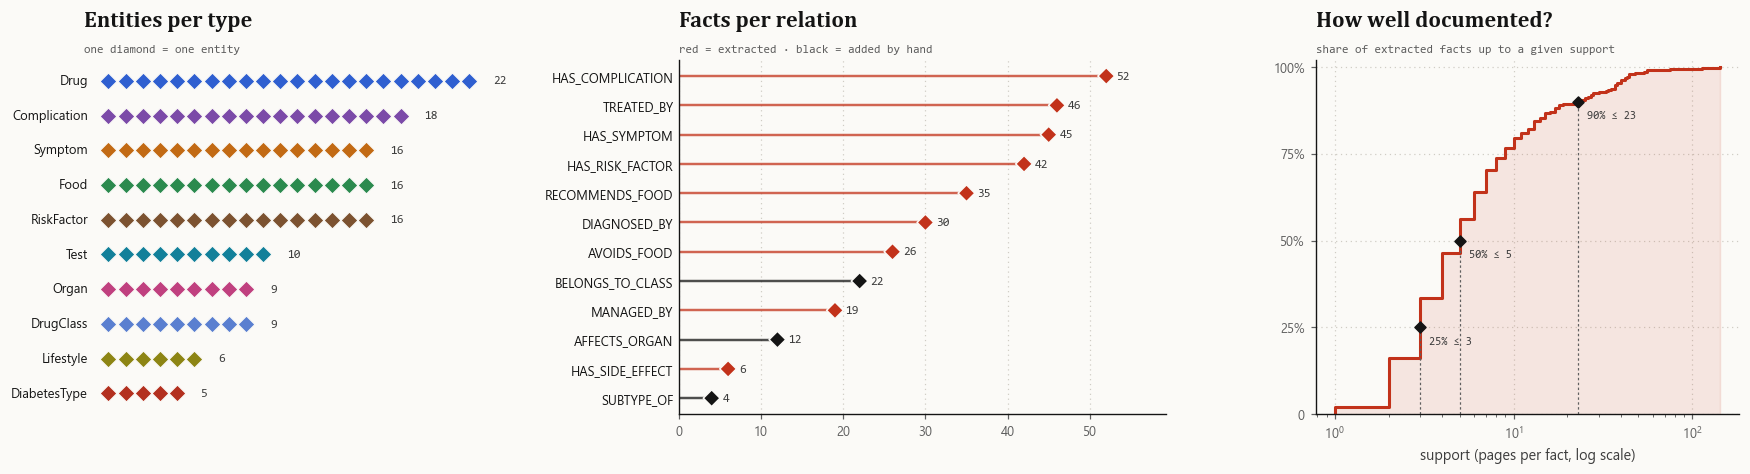

  support 25th percentile │ 3
  support 50th percentile │ 5
  support 75th percentile │ 9
  support 90th percentile │ 23
  largest support         │ 143


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1.05, 1.15, 1]})
V.unit_chart(ax[0], ent.label.value_counts().to_dict(), TYPE_COLORS)
atlas.title(ax[0], "Entities per type", "one diamond = one entity")
rel = tri.relation.value_counts()
V.lollipop(ax[1], list(rel.index), rel.values, colors=[INK if s == "curated" else ACCENT for s in tri.groupby("relation").source.first()[rel.index]])
atlas.title(ax[1], "Facts per relation", "red = extracted · black = added by hand")
V.ecdf(ax[2], ext.support, log=True, marks=(.25, .5, .9)); ax[2].set_xlabel("support (pages per fact, log scale)")
atlas.title(ax[2], "How well documented?", "share of extracted facts up to a given support")
plt.tight_layout(); plt.show()
q = ext.support.quantile([.25, .5, .75, .9])
kv({f"support {int(k*100)}th percentile": int(v) for k, v in q.items()} | {"largest support": int(ext.support.max())})

### Reading these charts

- **Entities per type.** Drugs, complications, risk factors, symptoms and foods each have 16 to 22 entities, roughly the size of their vocabulary lists, so almost every entry was found with enough support.
- **Support.** This is the most telling chart. The typical fact has support 5, but a few are repeated by dozens: "diabetes is treated with insulin" by 143 pages, "managed by regular exercise" by 114. That is how a health site behaves: the core message (exercise, diet, insulin, the main complications) is in nearly every article, while specific facts (which class a newer drug belongs to) are written once or twice. So support is also a measure of **how central a fact is** to how Vinmec talks about diabetes.

### 4.1 Do the types really differ?

If giving each type its own subject (3.4) worked, the types should show different facts. The bubble charts count, for each complication and symptom, how many pages support it per type; bigger bubble = more pages, no bubble = no such fact.

Two things stand out:

- the **general** column is the largest, the consequence of 3.4;
- **gestational** diabetes has its own pattern. Its strongest complications are hypoglycaemia (of the mother on treatment and of the newborn), pre-eclampsia, premature birth and a very large baby, all pregnancy complications the other types lack, while types 1 and 2 share the classic long-term damage to eyes, kidneys, nerves and heart. That is medically right, and shows the subject rule captures a real difference.

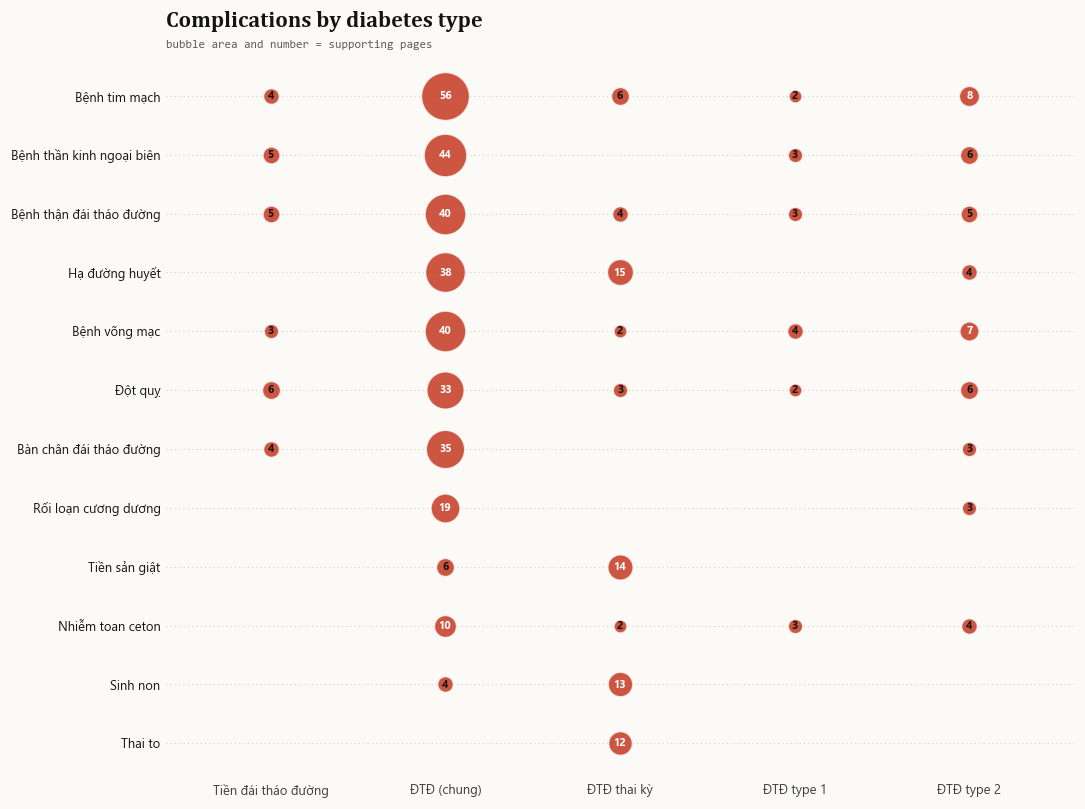

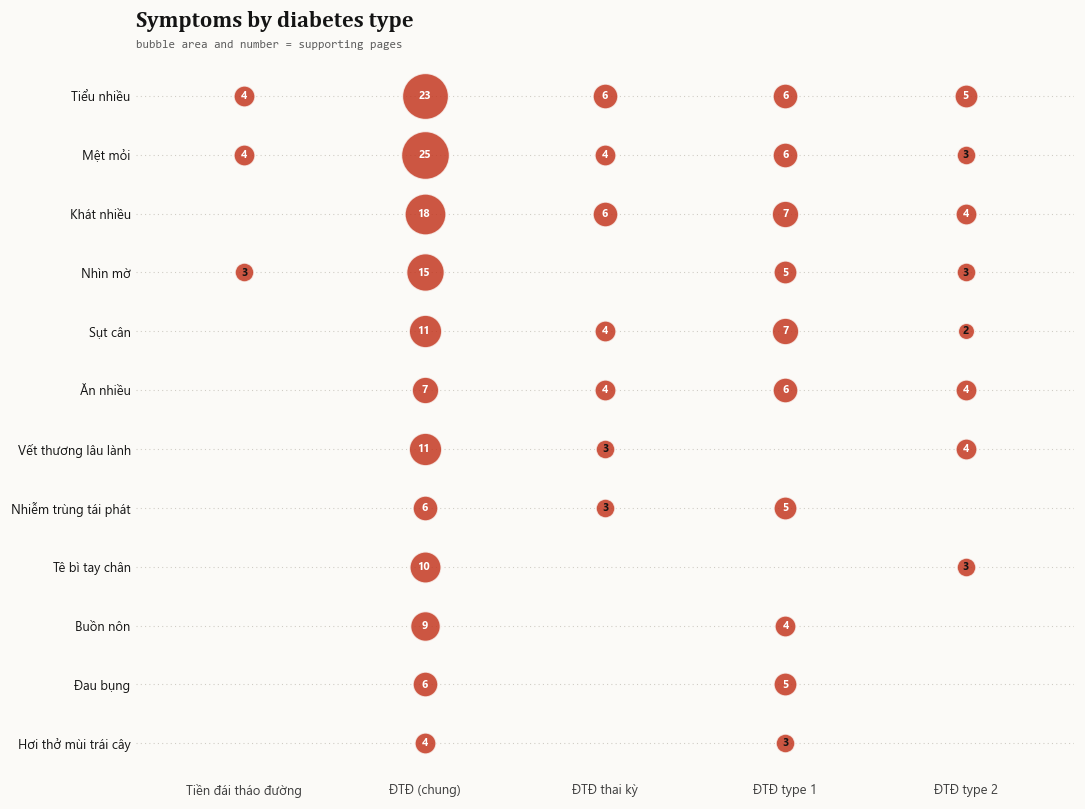

In [16]:
def bubbles(rel, title, top=12):
    sub = tri[tri.relation == rel].pivot_table(index="object", columns="subject", values="support", fill_value=0)
    sub = sub.loc[sub.sum(axis=1).sort_values(ascending=False).index[:top]]
    sub.columns = ["ĐTĐ (chung)" if c == "Đái tháo đường" else c.replace("Đái tháo đường", "ĐTĐ") for c in sub.columns]
    V.bubble_matrix(sub, title, "bubble area and number = supporting pages")
    plt.show()

bubbles("HAS_COMPLICATION", "Complications by diabetes type")
bubbles("HAS_SYMPTOM", "Symptoms by diabetes type")

## 5 · Moving into Neo4j

### Why a graph database at all?

The NetworkX graph of Part 1 lives in the memory of one Python program. When the program ends it is gone, and every other program must rebuild it from the CSV files. A real system needs the knowledge to be:

- **stored permanently**,
- **shared** by several programs (a notebook, a chatbot, a web page),
- **answered quickly**.

One could keep the facts in an ordinary table database such as MySQL, as a table of three columns. But questions about a graph are questions about **paths**: "start here, follow these arrows, then those". In a table database every step along a path is a *join* of the table with itself; queries grow long and hard to read, and they slow down as the table grows. A **graph database** stores each node with direct links to its neighbours, so following an arrow is a jump, not a search. **Neo4j** is the most widely used one, and its query language **Cypher** describes paths so that a question looks almost like a drawing of the path.

### 5.1 How the data is modelled

```
(:Entity:Symptom {name})                 every entity has the label Entity plus its own type
(:Entity:Test {name, threshold})
(:DiabetesType)-[:HAS_SYMPTOM {support, source, example_urls}]->(:Symptom)
(:Article {url, title, page_type, date})-[:ABOUT]->(:DiabetesType)
(:Article)-[:MENTIONS]->(:Entity)
```

Three decisions deserve a reason:

- **Two labels per entity**, `Entity` and its type. The type label lets us ask for "all symptoms". The shared `Entity` label lets one rule cover everything (every name is unique, so there can never be two "Metformin" nodes) and lets us write "everything connected to Metformin" without knowing the type of each neighbour.
- **Evidence lives on the arrows.** `support` and `example_urls` are properties of each relationship, so one query can return the answer, how well documented it is, *and* which articles state it. Stored elsewhere, every answer would need a second lookup.
- **Articles are nodes too.** Each of the 1,096 articles is an `Article` node linked to the entities it mentions and to the diabetes type it is about. That keeps the thread from the tidy facts back to the messy original text, which is what answers "where does this fact come from?" and is essential in medicine, where nobody should trust an answer they cannot check.

### 5.2 How it is loaded (`kg/load.py`)

```cypher
CREATE CONSTRAINT entity_name FOR (e:Entity) REQUIRE e.name IS UNIQUE;

UNWIND $rows AS r
MERGE (e:Entity {name: r.name}) SET e:Symptom;

UNWIND $rows AS r
MATCH (h:Entity {name: r.subject}), (t:Entity {name: r.object})
MERGE (h)-[x:HAS_SYMPTOM]->(t) SET x.support = r.support;
```

- **`MERGE`, not `CREATE`.** `CREATE` always adds a new node, even if an identical one exists; `MERGE` looks first and creates only when missing. Running the loader twice does not double every fact.
- **`UNWIND` sends a whole batch.** Every request has a fixed cost. 10,000 mention links one by one would be 10,000 round trips; `UNWIND` sends the list once and lets the database loop, so everything loads in seconds.
- **The uniqueness rule is also an index.** To keep names unique, Neo4j indexes `name`, so every query that starts at "the node called Metformin" jumps straight to it instead of scanning.
- **Relation types are written into the query text.** Cypher does not let an arrow's type be a parameter, so the loader groups facts by relation and builds one query per type.

The next cell connects and counts what is inside.

In [17]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver("bolt://localhost:7687", auth=("neo4j", "diabetes123"))
driver.verify_connectivity()

def cy(query, **params):
    """Run a Cypher query and return a DataFrame."""
    with driver.session() as s:
        return pd.DataFrame(s.run(query, **params).data())

def ask(query, title=None, **kw):
    """Run a query and print the answer as a boxed table."""
    tbl(cy(query, **{k: v for k, v in kw.items() if k not in ("limit", "note")}), title, **{k: v for k, v in kw.items() if k in ("limit", "note")})

nodes = cy("MATCH (n) UNWIND labels(n) AS l WITH l WHERE l <> 'Entity' RETURN l AS label, count(*) AS nodes ORDER BY nodes DESC")
rels = cy("MATCH ()-[r]->() RETURN type(r) AS relationship, count(*) AS edges ORDER BY edges DESC")
rule("inside Neo4j")
kv({"bolt": "localhost:7687", "node labels": len(nodes), "relationship types": len(rels),
    "nodes": int(nodes.nodes.sum()),
    "relationships": int(rels.edges.sum())})
tbl(nodes, "nodes by label"); tbl(rels, "relationships by type")


━━━ inside Neo4j ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  bolt               │ localhost:7687
  node labels        │ 11
  relationship types │ 14
  nodes              │ 1223
  relationships      │ 11518

▎nodes by label
┌──────────────┬───────┐
│ LABEL        │ NODES │
├──────────────┼───────┤
│ Article      │  1096 │
│ Drug         │    22 │
│ Complication │    18 │
│ Symptom      │    16 │
│ RiskFactor   │    16 │
│ Food         │    16 │
│ Test         │    10 │
│ DrugClass    │     9 │
│ Organ        │     9 │
│ Lifestyle    │     6 │
│ DiabetesType │     5 │
└──────────────┴───────┘
  11 rows

▎relationships by type
┌──────────────────┬───────┐
│ RELATIONSHIP     │ EDGES │
├──────────────────┼───────┤
│ MENTIONS         │ 10083 │
│ ABOUT            │  1096 │
│ HAS_COMPLICATION │    52 │
│ TREATED_BY       │    46 │
│ HAS_SYMPTOM      │    45 │
│ HAS_RISK_FACTOR  │    42 │
│ RECOMMENDS_FOOD  │    35 │
│ DIAGNOSED_BY     │    30 │
│ AVOIDS_FOOD     

### 5.3 The shape of the graph: which questions it can answer

Neo4j can describe its own structure: which node types are joined by which arrows, and how many. The picture below draws it as **ribbons**: boxes are entity types, and the width of a ribbon is the number of facts of that kind.

It is the best summary of what the graph *can* answer, because every ribbon is a kind of question:

- a ribbon from DiabetesType to Test means "how is it diagnosed?" is answerable;
- a ribbon from Complication to Organ lets a walk continue from a complication to the body part;
- there is **no** ribbon from Food to Complication, so "which food prevents kidney disease?" is out of reach, not because the articles never discuss it, but because we never extracted that kind of fact.

The picture also shows the layers: diabetes types on the left, what the articles say about them in the middle, and the hand-added classifications (drug classes, organs) on the right.

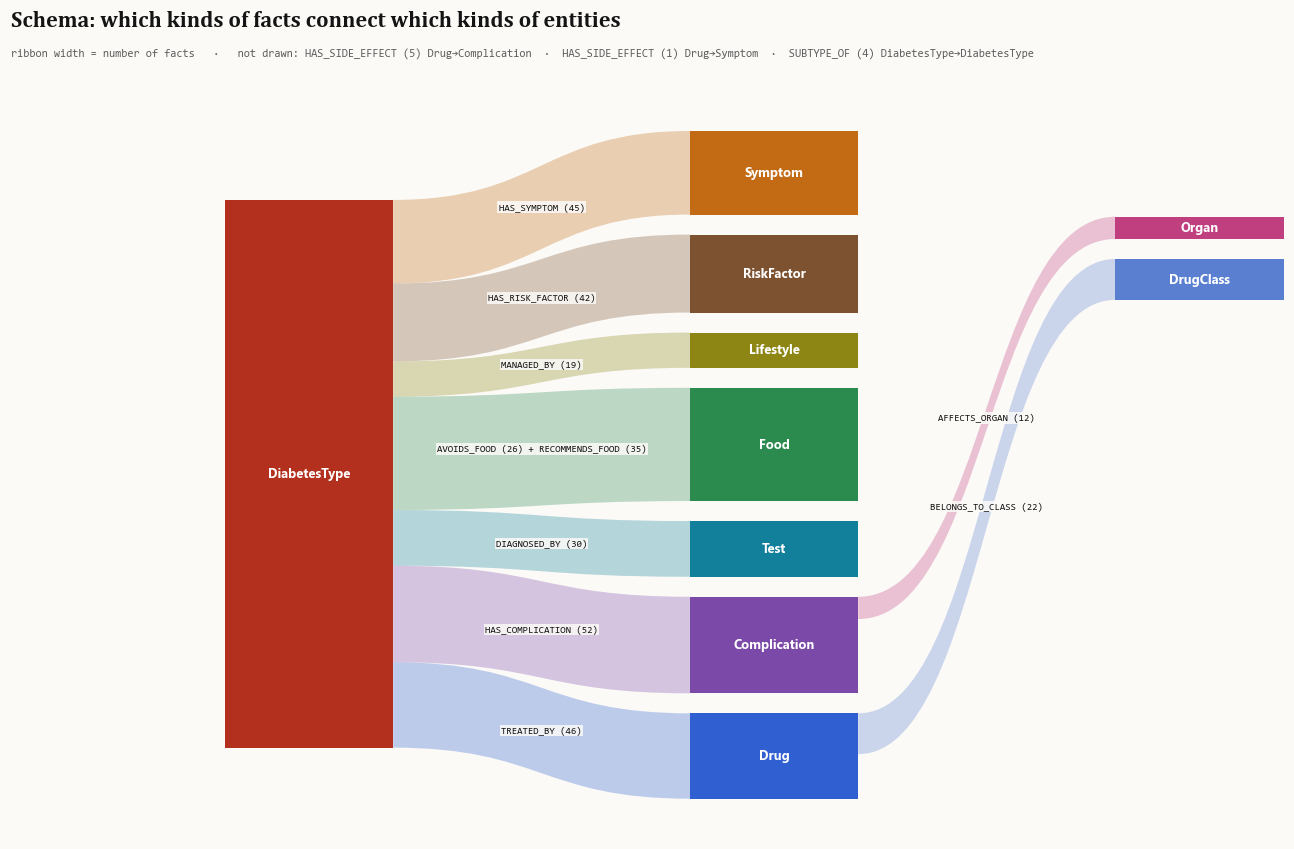

In [18]:
meta = cy("""
MATCH (a)-[r]->(b) WHERE NOT a:Article
WITH [l IN labels(a) WHERE l <> 'Entity'][0] AS src, type(r) AS rel, [l IN labels(b) WHERE l <> 'Entity'][0] AS dst, count(*) AS n
RETURN src, rel, dst, n""")
pairs = {}
for (s, d), grp in meta.groupby(["src", "dst"]):
    pairs[(s, d)] = (int(grp.n.sum()), " + ".join(f"{r.rel} ({r.n})" for r in grp.itertuples()))
V.draw_schema(pairs)
plt.show()

## 6 · Asking the graph

### How a Cypher question is written

Cypher describes the **shape of a path** with symbols that look like a drawing: round brackets for nodes, square brackets inside an arrow for relationships.

```cypher
MATCH (t:DiabetesType {name: 'Đái tháo đường type 2'})-[r:HAS_SYMPTOM]->(s:Symptom)
RETURN s.name, r.support
```

Read it left to right: *find a DiabetesType called "type 2", follow an outgoing HAS_SYMPTOM arrow to a Symptom, give me the symptom's name and the arrow's support.* The letters `t`, `r`, `s` are just names for the parts, so `RETURN` can use them.

How does Neo4j answer? It uses the name index to jump to the "type 2" node and looks only at the arrows attached to it. It never touches the rest of the database, which is why graph questions stay fast however big the graph grows: the work depends on how many arrows you follow, not on how large the database is.

All the questions below are also saved in `kg/queries.cypher`; paste them into Neo4j Browser at http://localhost:7474 to see the results drawn as a graph.

### 6.1 One hop: everything touching Metformin

In [19]:
ask("""
MATCH (e:Entity {name: 'Metformin'})-[r]-(n:Entity)
RETURN startNode(r).name AS subject, type(r) AS relation, endNode(r).name AS object, r.support AS support, r.source AS source
ORDER BY support DESC""", "Metformin · one hop, both directions")


▎Metformin · one hop, both directions
┌───────────────────────┬──────────────────┬────────────────┬─────────┬─────────┐
│ SUBJECT               │ RELATION         │ OBJECT         │ SUPPORT │ SOURCE  │
├───────────────────────┼──────────────────┼────────────────┼─────────┼─────────┤
│ Đái tháo đường        │ TREATED_BY       │ Metformin      │      37 │ vinmec  │
│ Đái tháo đường type 2 │ TREATED_BY       │ Metformin      │      11 │ vinmec  │
│ Tiền đái tháo đường   │ TREATED_BY       │ Metformin      │       8 │ vinmec  │
│ Metformin             │ HAS_SIDE_EFFECT  │ Hạ đường huyết │       5 │ vinmec  │
│ Metformin             │ BELONGS_TO_CLASS │ Biguanide      │       0 │ curated │
└───────────────────────┴──────────────────┴────────────────┴─────────┴─────────┘
  5 rows


The pattern `-[r]-` has no arrowhead, so it means "an arrow in **either** direction". That is why both kinds of fact appear: those pointing into Metformin (type 2 *is treated by* Metformin) and the one pointing out (Metformin *belongs to* the biguanide class). For "what do we know about X" direction is irrelevant, so we ask for both.

Look at the `support` column too:

- "diabetes is treated with Metformin" is stated by **37** articles;
- the side effect "hypoglycaemia" by only **5**;
- the drug class has support **0**, because it was added by hand (`source = curated`).

Showing support beside each fact lets the reader judge how solid each one is.

### 6.2 Two hops: which organs can type 2 damage?

This is the question from Part 1, now on the real graph. The path is type 2 → (`HAS_COMPLICATION`) → a complication → (`AFFECTS_ORGAN`) → an organ. No article states "type 2 damages the eye" in that form; the answer exists only because two kinds of fact meet at the complication: an extracted one (type 2 causes retinopathy) and a hand-added one (retinopathy affects the eye). `collect()` gathers all complications that lead to the same organ, so each organ appears once with its reasons.


▎organs reachable from type 2 in two hops
┌───────────┬──────────────────────────────────────────────────┬──────────┐
│ ORGAN     │ VIA_COMPLICATIONS                                │ EVIDENCE │
├───────────┼──────────────────────────────────────────────────┼──────────┤
│ Thần kinh │ Rối loạn cương dương · Bệnh thần kinh ngoại biên │        9 │
│ Mắt       │ Đục thủy tinh thể · Bệnh võng mạc                │        8 │
│ Tim mạch  │ Bệnh tim mạch                                    │        8 │
│ Não       │ Đột quỵ                                          │        6 │
│ Thận      │ Bệnh thận đái tháo đường                         │        5 │
│ Bàn chân  │ Bàn chân đái tháo đường                          │        3 │
│ Dạ dày    │ Liệt dạ dày                                      │        1 │
└───────────┴──────────────────────────────────────────────────┴──────────┘
  7 rows


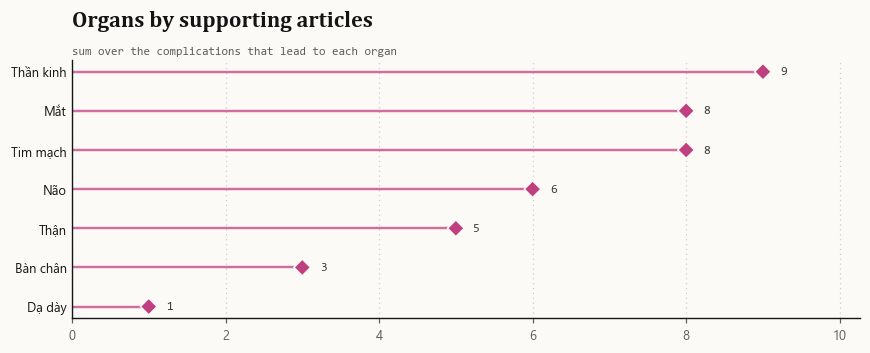

In [20]:
organs = cy("""
MATCH (t:DiabetesType {name: 'Đái tháo đường type 2'})-[r:HAS_COMPLICATION]->(c)-[:AFFECTS_ORGAN]->(o:Organ)
RETURN o.name AS organ, collect(c.name) AS via_complications, sum(r.support) AS evidence
ORDER BY evidence DESC""")
tbl(organs, "organs reachable from type 2 in two hops", limit=60)

fig, ax = plt.subplots(figsize=(8, 3.3))
V.lollipop(ax, organs.organ, organs.evidence.values, colors=[TYPE_COLORS["Organ"]] * len(organs))
atlas.title(ax, "Organs by supporting articles", "sum over the complications that lead to each organ")
plt.tight_layout(); plt.show()

### 6.3 Type 1 against type 2 symptoms

For each symptom we collect which of the two types it belongs to. A symptom with both types is *shared*; with one type, it is *specific* in the Vinmec articles.

What the result shows:

- The six classic symptoms (thirst, frequent urination, eating a lot, weight loss, fatigue, blurred vision) are **shared**, which is right: they come from high blood sugar itself, whatever its cause.
- Most **type 1-only** symptoms (nausea, abdominal pain, fruity-smelling breath) are signs of **ketoacidosis**, the dangerous acid build-up when the body has almost no insulin, typical of type 1 at discovery. (Recurrent infections also appear only for type 1; that is a general sign of high sugar that the type 2 articles simply did not list under a symptom heading.)
- The **type 2-only** symptoms (slow-healing wounds, numb hands and feet) appear after years of mildly high sugar, matching type 2's slow, often unnoticed course.

The graph reproduced a real medical difference without anyone telling it.

In [21]:
ask("""
MATCH (t:DiabetesType)-[r:HAS_SYMPTOM]->(s:Symptom)
WHERE t.name IN ['Đái tháo đường type 1', 'Đái tháo đường type 2']
WITH s, collect(t.name) AS types, collect(r.support) AS sup
RETURN s.name AS symptom, CASE size(types) WHEN 2 THEN 'both' ELSE types[0] END AS found_in, sup AS support
ORDER BY found_in, symptom""", "symptoms of type 1 and type 2")


▎symptoms of type 1 and type 2
┌──────────────────────┬───────────────────────┬─────────┐
│ SYMPTOM              │ FOUND_IN              │ SUPPORT │
├──────────────────────┼───────────────────────┼─────────┤
│ Khát nhiều           │ both                  │ 7 · 4   │
│ Mệt mỏi              │ both                  │ 6 · 3   │
│ Nhìn mờ              │ both                  │ 5 · 3   │
│ Sụt cân              │ both                  │ 7 · 2   │
│ Tiểu nhiều           │ both                  │ 6 · 5   │
│ Ăn nhiều             │ both                  │ 6 · 4   │
│ Buồn nôn             │ Đái tháo đường type 1 │ 4       │
│ Hơi thở mùi trái cây │ Đái tháo đường type 1 │ 3       │
│ Nhiễm trùng tái phát │ Đái tháo đường type 1 │ 5       │
│ Đau bụng             │ Đái tháo đường type 1 │ 5       │
│ Tê bì tay chân       │ Đái tháo đường type 2 │ 3       │
│ Vết thương lâu lành  │ Đái tháo đường type 2 │ 4       │
└──────────────────────┴───────────────────────┴─────────┘
  12 rows


### 6.4 A symptom finder

Given a list of symptoms, which diabetes type do they point to? The query finds all symptom facts whose symptom is in the list, groups them by type, and ranks by **how many of the given symptoms** each type has. Ties go to the larger total support, meaning the type the articles associate more strongly with these symptoms.

With {thirst, frequent urination, weight loss, blurred vision}, general diabetes, type 1 and type 2 all match all four; general comes first because most articles are general (3.4). Gestational matches three.

This shows both the use and the limit:

- it tells you which types are **associated** with these symptoms in the literature, and how strongly;
- it cannot tell a patient **which diabetes they have**: the classic symptoms are shared by all types, and diagnosis needs blood tests (exactly what 6.6 shows).

The finder retrieves information; it does not diagnose.

In [22]:
res = cy("""
WITH $input AS input
MATCH (t:DiabetesType)-[r:HAS_SYMPTOM]->(s:Symptom) WHERE s.name IN input
RETURN t.name AS type, count(s) AS matched, collect(s.name) AS symptoms, sum(r.support) AS evidence
ORDER BY matched DESC, evidence DESC""", input=["Khát nhiều", "Tiểu nhiều", "Sụt cân", "Nhìn mờ"])
rule("symptom finder · 4 symptoms in")
for r in res.itertuples():
    print(f"  {r.type:<26} {'▰' * r.matched}{'▱' * (4 - r.matched)}  {r.matched}/4   evidence {r.evidence}")


━━━ symptom finder · 4 symptoms in ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Đái tháo đường             ▰▰▰▰  4/4   evidence 67
  Đái tháo đường type 1      ▰▰▰▰  4/4   evidence 25
  Đái tháo đường type 2      ▰▰▰▰  4/4   evidence 14
  Đái tháo đường thai kỳ     ▰▰▰▱  3/4   evidence 16
  Tiền đái tháo đường        ▰▰▱▱  2/4   evidence 7


### 6.5 Following a chain: from a risk factor to an organ

A three-step path: risk factor ← (is a risk factor of) a diabetes type → (can cause) a complication → (affects) an organ. Each row is a complete chain of reasoning that can be told in plain words: *obesity is a risk factor for type 2; type 2 can cause diabetic kidney disease; that disease damages the kidneys.*

Chained explanations are the main thing a graph offers that a list of documents does not. Each step is a separate fact, possibly from different articles, and the graph joins them because they share a node.

In [23]:
paths = cy("""
MATCH p = (rf:RiskFactor {name: 'Thừa cân, béo phì'})<-[:HAS_RISK_FACTOR]-(t:DiabetesType)
          -[:HAS_COMPLICATION]->(c:Complication)-[:AFFECTS_ORGAN]->(o:Organ {name: 'Thận'})
RETURN [n IN nodes(p) | n.name] AS path""")
rule("obesity → kidney")
for i, p in enumerate(paths.path, 1):
    print(f"  {i}. " + "  ═▶  ".join(p))


━━━ obesity → kidney ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  1. Thừa cân, béo phì  ═▶  Tiền đái tháo đường  ═▶  Bệnh thận đái tháo đường  ═▶  Thận
  2. Thừa cân, béo phì  ═▶  Đái tháo đường type 2  ═▶  Bệnh thận đái tháo đường  ═▶  Thận
  3. Thừa cân, béo phì  ═▶  Đái tháo đường  ═▶  Bệnh thận đái tháo đường  ═▶  Thận
  4. Thừa cân, béo phì  ═▶  Đái tháo đường thai kỳ  ═▶  Bệnh thận đái tháo đường  ═▶  Thận


### 6.6 Diagnosis: which tests, at which values?

This answer joins the two kinds of knowledge. The link "diabetes is diagnosed by HbA1c" was **extracted** from the articles; the threshold "6.5 % or more" sits on the test node and was **added by hand** from the official guideline. Together they answer "how is diabetes diagnosed?" with real numbers. The `evidence` column shows that HbA1c and the glucose tolerance test are the tests the articles mention most.

In [24]:
ask("""
MATCH (t:DiabetesType)-[r:DIAGNOSED_BY]->(x:Test)
RETURN x.name AS test, x.threshold AS threshold, collect(t.name) AS used_for, sum(r.support) AS evidence
ORDER BY evidence DESC""", "diagnostic tests", limit=48)


▎diagnostic tests
┌─────────────────────────────────────┬─────────────────────────────────┬──────────────────────────────────────────────────┬──────────┐
│ TEST                                │ THRESHOLD                       │ USED_FOR                                         │ EVIDENCE │
├─────────────────────────────────────┼─────────────────────────────────┼──────────────────────────────────────────────────┼──────────┤
│ HbA1c                               │ ≥ 6.5%                          │ Đái tháo đường thai kỳ · Đái tháo đường type 1 … │       67 │
│ Nghiệm pháp dung nạp glucose (OGTT) │ 2 giờ ≥ 11.1 mmol/L (200 mg/dL) │ Đái tháo đường · Đái tháo đường type 1 · Đái th… │       59 │
│ Đường huyết lúc đói                 │ ≥ 7.0 mmol/L (126 mg/dL)        │ Đái tháo đường type 1 · Đái tháo đường · Tiền đ… │       51 │
│ Xét nghiệm nước tiểu                │                                 │ Đái tháo đường · Đái tháo đường type 1 · Đái th… │       14 │
│ Soi đáy mắt                

### 6.7 Drugs by class, with their side effects

Each drug is listed with its class (hand-added), the number of articles that name it as a treatment, and any side effects extracted from sentences (3.8). Insulin is by far the most discussed (143 articles), then Metformin (37), which matches practice: Metformin is the first drug for type 2, and insulin is essential for type 1 and advanced type 2.

Look closely at insulin's side effects: one is *ketoacidosis*, and that is **wrong**. Ketoacidosis comes from a *lack* of insulin, not from taking it, and the "thiếu" filter of 3.8 did not catch every phrasing. It is a real extraction error left in the graph on purpose, and it is listed in Part 10.

The query uses `OPTIONAL MATCH` for side effects. A normal `MATCH` drops a drug entirely if it has no side-effect fact, because the whole pattern must match. `OPTIONAL MATCH` means "include this part if it exists, else leave it empty", so drugs without side effects are still listed.

In [25]:
ask("""
MATCH (d:Drug)-[:BELONGS_TO_CLASS]->(c:DrugClass)
OPTIONAL MATCH (d)-[se:HAS_SIDE_EFFECT]->(e)
OPTIONAL MATCH (:DiabetesType {name: 'Đái tháo đường'})-[tr:TREATED_BY]->(d)
RETURN c.name AS class, d.name AS drug, coalesce(tr.support, 0) AS articles, collect(e.name) AS side_effects
ORDER BY class, articles DESC""", "drugs grouped by class", limit=34)


▎drugs grouped by class
┌──────────────────────────┬──────────────────┬──────────┬────────────────────────────────────┐
│ CLASS                    │ DRUG             │ ARTICLES │ SIDE_EFFECTS                       │
├──────────────────────────┼──────────────────┼──────────┼────────────────────────────────────┤
│ Biguanide                │ Metformin        │       37 │ Hạ đường huyết                     │
│ Meglitinide              │ Repaglinide      │        6 │                                    │
│ Nhóm Insulin             │ Insulin          │      143 │ Nhiễm toan ceton · Hạ đường huyết… │
│ Nhóm Insulin             │ Insulin glargine │       13 │                                    │
│ Nhóm Insulin             │ Insulin aspart   │       11 │                                    │
│ Nhóm Insulin             │ Insulin lispro   │        9 │                                    │
│ Nhóm Insulin             │ Insulin NPH      │        6 │                                    │
│ Sulfonylurea 

### 6.8 Diet for gestational diabetes

The foods discussed in diet sections of gestational-diabetes articles, split into *recommended* and *to avoid* (the split comes from the fixed food list in 3.7), with the number of articles for each. Sweets are the most discussed food to avoid; green vegetables, eggs and whole grains the most recommended, consistent with the usual advice for pregnant women with diabetes.


▎foods in gestational-diabetes diet sections
┌─────────────────┬──────────────────────────────┬──────────┐
│ ADVICE          │ FOOD                         │ ARTICLES │
├─────────────────┼──────────────────────────────┼──────────┤
│ AVOIDS_FOOD     │ Đồ ngọt, bánh kẹo            │       14 │
│ AVOIDS_FOOD     │ Thịt chế biến sẵn            │        7 │
│ AVOIDS_FOOD     │ Nước ngọt có ga              │        7 │
│ AVOIDS_FOOD     │ Rượu bia                     │        6 │
│ AVOIDS_FOOD     │ Đồ chiên rán, mỡ động vật    │        6 │
│ AVOIDS_FOOD     │ Trái cây nhiều đường         │        4 │
│ AVOIDS_FOOD     │ Cơm trắng, tinh bột tinh chế │        2 │
│ RECOMMENDS_FOOD │ Rau xanh                     │       13 │
│ RECOMMENDS_FOOD │ Trứng                        │       12 │
│ RECOMMENDS_FOOD │ Ngũ cốc nguyên hạt           │       10 │
│ RECOMMENDS_FOOD │ Các loại đậu                 │        8 │
│ RECOMMENDS_FOOD │ Sữa chua không đường         │        7 │
│ RECOMMENDS_FOOD │ Các 

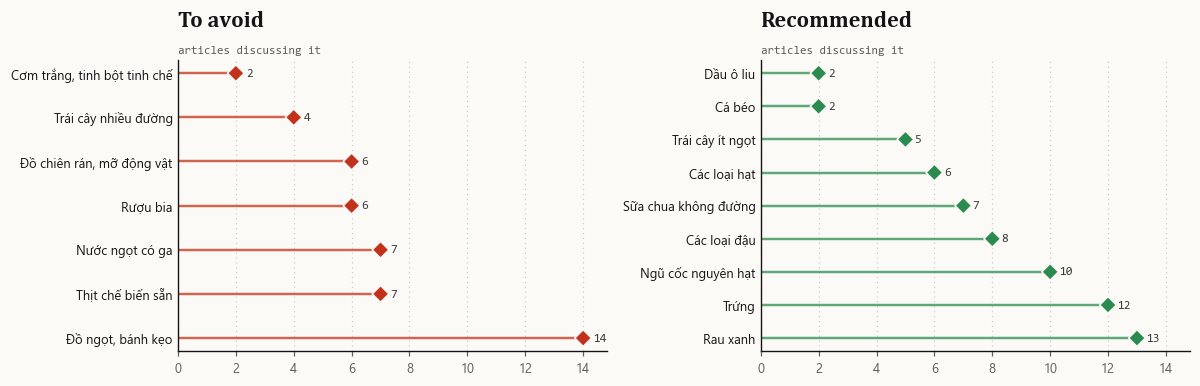

In [26]:
diet = cy("""
MATCH (:DiabetesType {name: 'Đái tháo đường thai kỳ'})-[r:RECOMMENDS_FOOD|AVOIDS_FOOD]->(f:Food)
RETURN type(r) AS advice, f.name AS food, r.support AS articles
ORDER BY advice, articles DESC""")
tbl(diet, "foods in gestational-diabetes diet sections")

avoid, rec = diet[diet.advice == "AVOIDS_FOOD"].iloc[::-1], diet[diet.advice == "RECOMMENDS_FOOD"].iloc[::-1]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
V.lollipop(a1, avoid.food, avoid.articles.values, colors=[ACCENT] * len(avoid)); atlas.title(a1, "To avoid", "articles discussing it")
V.lollipop(a2, rec.food, rec.articles.values, colors=[TYPE_COLORS["Food"]] * len(rec)); atlas.title(a2, "Recommended", "articles discussing it")
plt.tight_layout(); plt.show()

### 6.9 Where does a fact come from?

Every fact stores up to five example article URLs. Here we take "type 2 can cause diabetic kidney disease", unpack its URLs and look up the article nodes for their titles. The result is a list of real Vinmec articles that state the fact, which anyone can open and read.

This is what makes a knowledge graph trustworthy for health. A language model can say something fluent and wrong with no way to check; here **every answer traces back to its source**.

In [27]:
ask("""
MATCH (:DiabetesType {name: 'Đái tháo đường type 2'})-[r:HAS_COMPLICATION]->(:Complication {name: 'Bệnh thận đái tháo đường'})
UNWIND r.example_urls AS url
MATCH (a:Article {url: url})
RETURN a.title AS article, a.url AS url""", "sources of one fact", limit=70)


▎sources of one fact
┌────────────────────────────────────────────────────────────────────────┬────────────────────────────────────────────────────────────────────────┐
│ ARTICLE                                                                │ URL                                                                    │
├────────────────────────────────────────────────────────────────────────┼────────────────────────────────────────────────────────────────────────┤
│ Bệnh tiểu đường type 2 có nguy hiểm không?                             │ https://www.vinmec.com/vie/bai-viet/benh-tieu-duong-type-2-co-nguy-hi… │
│ Bệnh tiểu đường type 2: Nguyên nhân, biến chứng và phòng bệnh          │ https://www.vinmec.com/vie/bai-viet/benh-tieu-duong-type-2-nguyen-nha… │
│ Các biến chứng nguy hiểm của bệnh đái tháo đường type 2                │ https://www.vinmec.com/vie/bai-viet/cac-bien-chung-nguy-hiem-cua-benh… │
│ Cách tự nhiên điều trị bệnh tiểu đường type 2 với những thực phẩm hàn… │ https://www.vin

### 6.10 Which complications are written about together?

The `MENTIONS` links (article → every entity it mentions anywhere) give a second, looser kind of information: which topics share articles. Here we count, for each pair of complications, the articles that mention both.

This is **not** a fact about diabetes (appearing together does not mean one causes the other), but it shows how Vinmec writes. Cardiovascular disease and hypoglycaemia lead simply because each appears in a huge share of all articles. That is the general weakness of raw co-occurrence: pairs of common topics always rank first, related or not. Finding pairs that are *unusually* frequent would mean comparing each count with what each topic's own popularity predicts.

In [28]:
ask("""
MATCH (a:Article)-[:MENTIONS]->(c1:Complication), (a)-[:MENTIONS]->(c2:Complication)
WHERE c1.name < c2.name
RETURN c1.name AS complication_1, c2.name AS complication_2, count(a) AS articles_together
ORDER BY articles_together DESC LIMIT 10""", "complication pairs sharing the most articles")


▎complication pairs sharing the most articles
┌───────────────────────────┬──────────────────────────┬───────────────────┐
│ COMPLICATION_1            │ COMPLICATION_2           │ ARTICLES_TOGETHER │
├───────────────────────────┼──────────────────────────┼───────────────────┤
│ Bệnh tim mạch             │ Hạ đường huyết           │               170 │
│ Bệnh thận đái tháo đường  │ Bệnh tim mạch            │               163 │
│ Bệnh tim mạch             │ Đột quỵ                  │               139 │
│ Bệnh thận đái tháo đường  │ Hạ đường huyết           │               116 │
│ Bệnh thần kinh ngoại biên │ Bệnh tim mạch            │               110 │
│ Bệnh thận đái tháo đường  │ Bệnh võng mạc            │               107 │
│ Bệnh thần kinh ngoại biên │ Bệnh thận đái tháo đường │               100 │
│ Bệnh tim mạch             │ Bệnh võng mạc            │                98 │
│ Bệnh thận đái tháo đường  │ Đột quỵ                  │                95 │
│ Bệnh thần kinh ngoại biên │

## 7 · Bounded retrieval: `graph_facts(entity, hops)`

In a full question-answering system (the lecture's KG + RAG architecture) a language model writes the answer, and the graph's job is to hand it a **small set of relevant, reliable facts**. `kg/retriever.py` does exactly this:

1. find the node for the entity in the question;
2. collect the facts within one step (or two) of it;
3. turn each fact into a short sentence, "subject RELATION object.";
4. sort by support so the best-documented come first, and return at most 30.

Why not return everything connected? Because in a graph almost everything is connected to everything within a few steps, especially through hub nodes. The chart makes this concrete: one hop around an entity gives a handful of precise facts; two hops multiply them, because one first-step neighbour is "Đái tháo đường", which touches almost the whole graph. Feeding 230 facts to a language model for a question about hypoglycaemia would bury the five relevant ones. This is the lecture's "graph retrieval too broad" problem, and the cure is the one used here: start at the entity, stay within one or two hops, then rank and cut.


━━━ 1 hop from 'Hạ đường huyết' ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
   1. Đái tháo đường HAS_COMPLICATION Hạ đường huyết.
   2. Insulin HAS_SIDE_EFFECT Hạ đường huyết.
   3. Đái tháo đường thai kỳ HAS_COMPLICATION Hạ đường huyết.
   4. Metformin HAS_SIDE_EFFECT Hạ đường huyết.
   5. Đái tháo đường type 2 HAS_COMPLICATION Hạ đường huyết.

▎how fast the neighbourhood explodes
┌───────────────────┬───────┬────────┐
│ ENTITY            │ 1 HOP │ 2 HOPS │
├───────────────────┼───────┼────────┤
│ Hạ đường huyết    │     5 │    230 │
│ Metformin         │     5 │    210 │
│ HbA1c             │     5 │    299 │
│ Thận              │     1 │      6 │
│ Thừa cân, béo phì │     4 │    255 │
└───────────────────┴───────┴────────┘
  5 rows


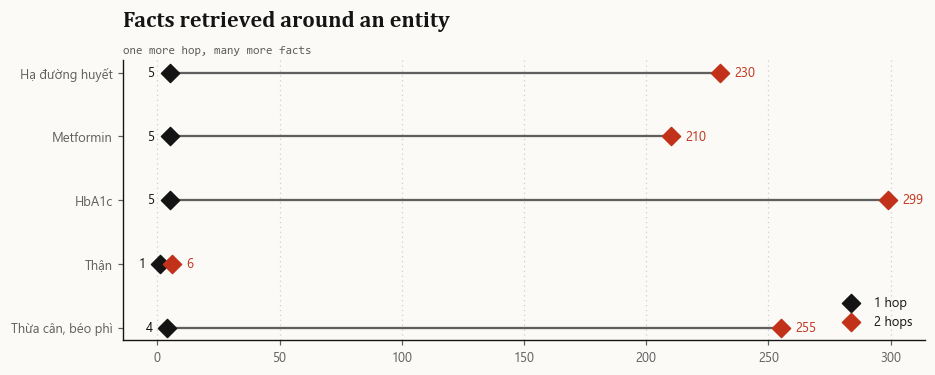

In [29]:
from retriever import graph_facts

rule("1 hop from 'Hạ đường huyết'")
for i, f in enumerate(graph_facts(driver, "Hạ đường huyết", hops=1), 1):
    print(f"  {i:>2}. {f}")

probe = ["Hạ đường huyết", "Metformin", "HbA1c", "Thận", "Thừa cân, béo phì"]
sizes = pd.DataFrame([(e, len(graph_facts(driver, e, 1, 10_000)), len(graph_facts(driver, e, 2, 10_000))) for e in probe],
                     columns=["entity", "1 hop", "2 hops"])
tbl(sizes, "how fast the neighbourhood explodes")

fig, ax = plt.subplots(figsize=(8.6, 3.5))
y = np.arange(len(sizes))
ax.hlines(y, sizes["1 hop"], sizes["2 hops"], color=INK_FAINT, lw=1.5)
ax.scatter(sizes["1 hop"], y, marker="D", s=70, color=INK, label="1 hop", zorder=3)
ax.scatter(sizes["2 hops"], y, marker="D", s=70, color=ACCENT, label="2 hops", zorder=3)
for yi, a, b in zip(y, sizes["1 hop"], sizes["2 hops"]):
    ax.text(b + 6, yi, f"{b}", va="center", fontsize=8.5, color=ACCENT); ax.text(a - 6, yi, f"{a}", va="center", ha="right", fontsize=8.5, color=INK)
ax.set_yticks(y, sizes.entity); ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.legend(loc="lower right")
atlas.title(ax, "Facts retrieved around an entity", "one more hop, many more facts"); plt.tight_layout(); plt.show()

## 8 · Seeing the graph, and finding what matters

For drawing and measuring, the graph is rebuilt in NetworkX from the **same CSV files** that were loaded into Neo4j, so both hold exactly the same facts.

### 8.1 The whole graph

A force-directed layout of 127 nodes and 339 edges turns into a hairball, so this notebook draws the graph on a **ring** instead:

- entities sit on a circle, **grouped by type** (the coloured arcs name the groups);
- every fact is a **chord**, coloured by the type it starts from, thicker when more articles support it, dashed when added by hand;
- the five diabetes types at the top are the hubs: nearly every chord begins there.

Out of all arrows that could exist between 127 entities only about 2 % are present: each entity connects to a few others, not to everything. Graphs of real knowledge are almost always this **sparse**, and it is what keeps graph queries fast.


━━━ NetworkX copy of the graph ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  nodes                       │ 127
  edges                       │ 339
  density                     │ 0.021
  weakly connected components │ 1


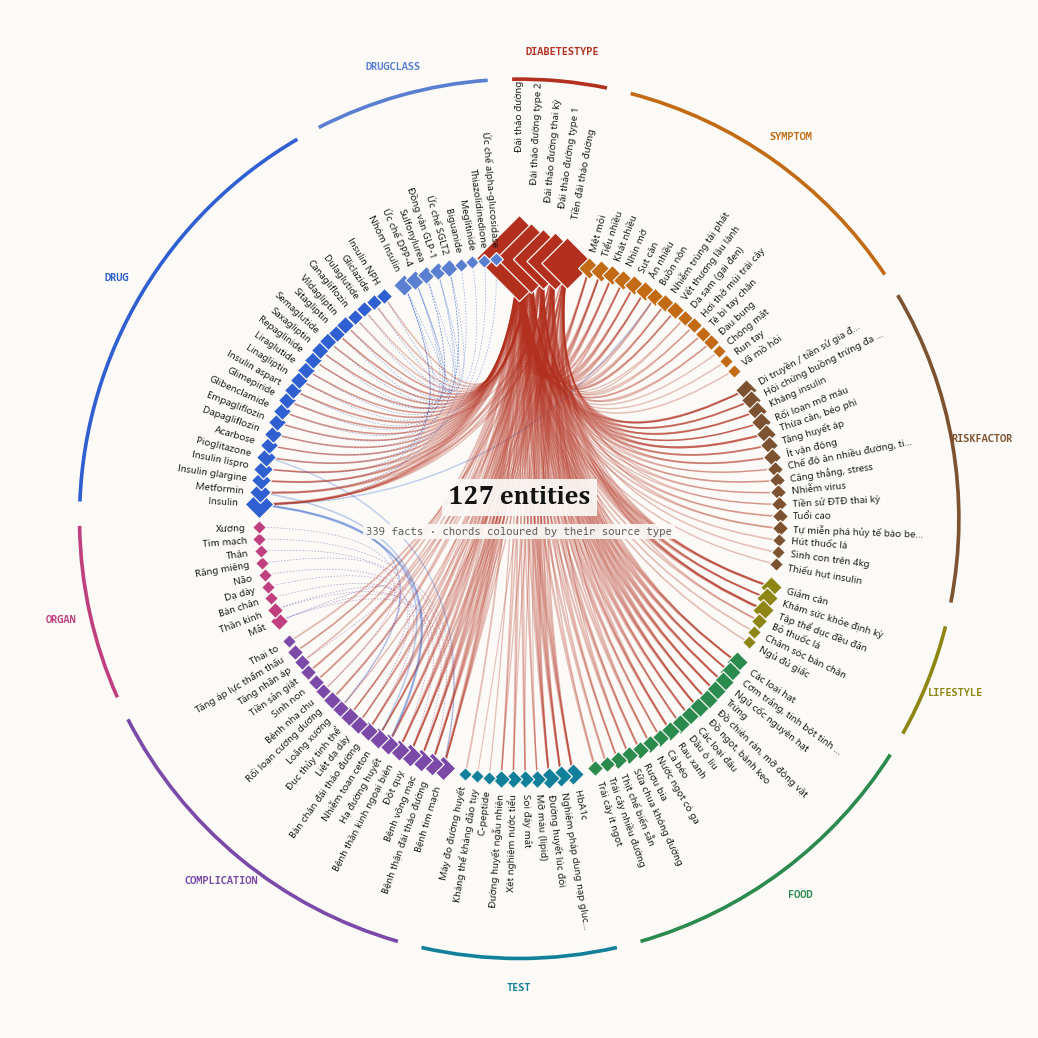

In [30]:
G = V.build_graph()
rule("NetworkX copy of the graph")
kv({"nodes": G.number_of_nodes(), "edges": G.number_of_edges(), "density": f"{nx.density(G):.3f}",
    "weakly connected components": nx.number_weakly_connected_components(G)})
V.draw_ring(G, size=(12, 12))
plt.show()

### 8.2 One part at a time

The ring shows structure but not detail. Two closer views:

- **Gestational diabetes at the centre.** Its neighbours are placed on a ring and grouped by relation, so you can read off everything the graph knows: symptoms, pregnancy-specific complications, tests, foods to avoid and to prefer.
- **Type 2 treatment as an arc diagram.** Drugs sit on a line, grouped by class (the brackets below). Blue arcs above join type 2 to each drug that treats it; red arcs join a drug to its extracted side effects. The drug families appear as neighbours, which is how doctors think of them, and the red arcs show the most discussed risk of treatment, hypoglycaemia, reached from both insulin and Metformin.

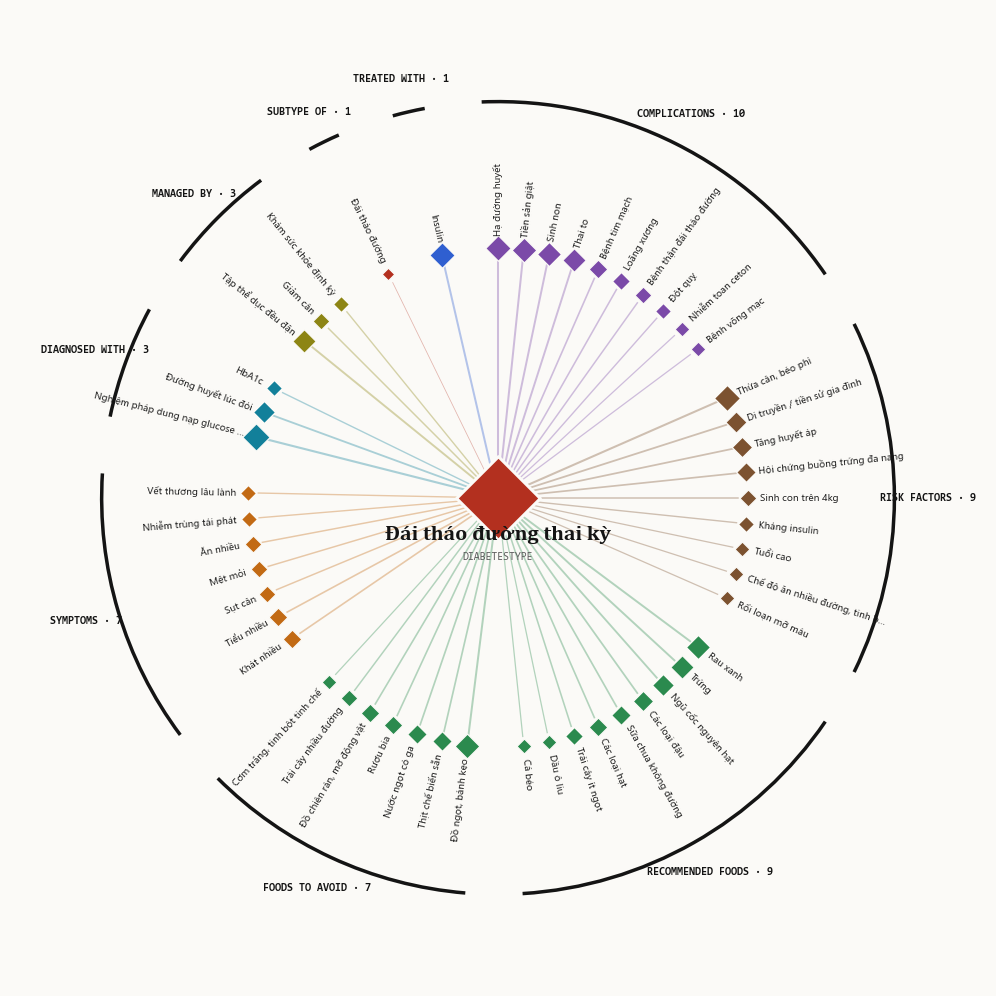

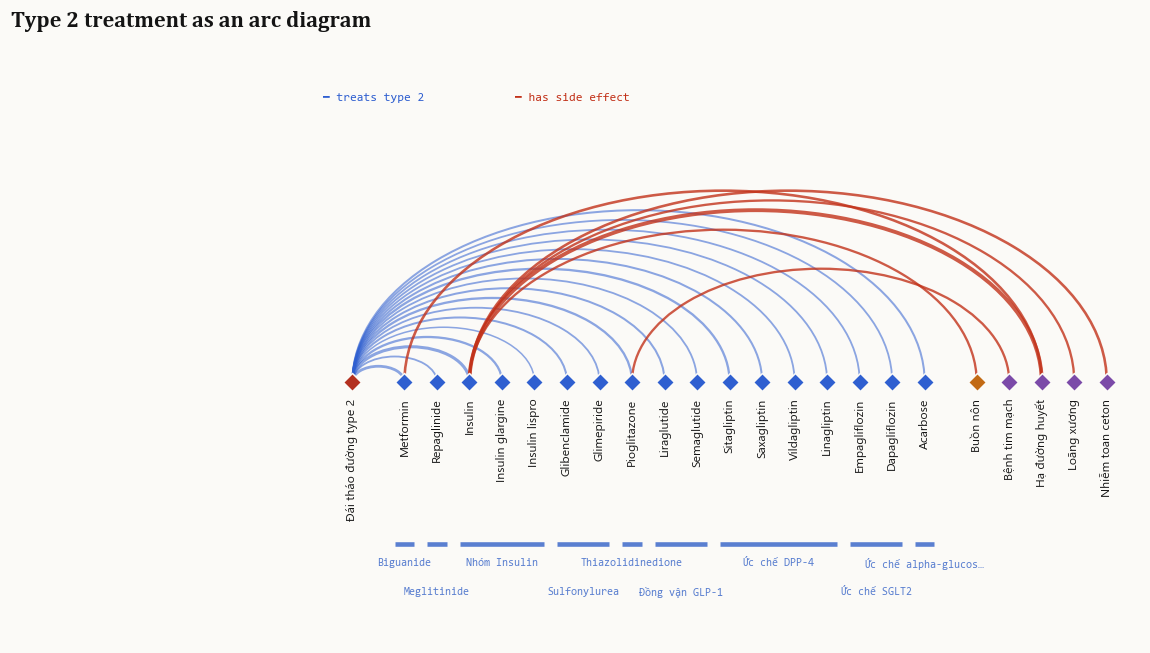

In [31]:
V.draw_ego(G, "Đái tháo đường thai kỳ", size=(11.5, 11.5), label_size=6.6)
plt.show()
V.draw_arcs(G)
plt.show()

### 8.3 Which entities matter most?

"Important" can mean different things for a node, and two common measures give quite different answers. Understanding why teaches you about the graph itself.

- **Degree** is the simplest: the number of arrows touching a node. It answers "how many facts involve this entity?" and looks only at the node's own arrows.
- **PageRank** is what Google first used to rank web pages. A node is important if *important* nodes point to it. Picture a walker: start on a random node; at each step either follow one of the current node's outgoing arrows at random, or, now and then, get bored and jump to a random node. After a very long walk, PageRank is the share of time spent on each node.

**What happens here.** Our arrows all point *away* from the diabetes types: type → drug → drug class, type → complication → organ. A walker following arrows drifts down these chains and gets stuck at the ends (drug classes and organs have no outgoing arrows) until the next random jump. So directed PageRank ranks "Nhóm Insulin", "Ức chế DPP-4" and "Mắt" (eye) highest. They are not what the articles are mostly about; they are where many paths **end**.

The direction of our arrows is our own modelling choice ("type 2 HAS_SYMPTOM thirst" could equally be "thirst SYMPTOM_OF type 2"). A measure whose answer flips when you rename a relation is not measuring what we want. So we also compute PageRank **ignoring direction**, as if every arrow could be walked both ways. Then a node matters if it is well connected to other well-connected nodes. That ranking makes sense: the diabetes types first, then insulin, cardiovascular disease, stroke, kidney disease, retinopathy and Metformin, the treatments and complications that tie the graph together.

The lesson: **a graph measure answers a specific question, and you must check it is the one you want to ask.** The dumbbell chart puts both answers side by side.


━━━ two PageRanks, two stories ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

▎top 5 by directed PageRank (dead ends of the chains)
┌────────────────┬───────────┬────────┬──────────┬────────────┐
│ ENTITY         │ TYPE      │ DEGREE │ DIRECTED │ UNDIRECTED │
├────────────────┼───────────┼────────┼──────────┼────────────┤
│ Nhóm Insulin   │ DrugClass │      5 │    0.029 │      0.008 │
│ Ức chế DPP-4   │ DrugClass │      4 │    0.028 │      0.007 │
│ Mắt            │ Organ     │      3 │    0.023 │      0.005 │
│ Đồng vận GLP-1 │ DrugClass │      3 │    0.022 │      0.006 │
│ Ức chế SGLT2   │ DrugClass │      3 │    0.022 │      0.006 │
└────────────────┴───────────┴────────┴──────────┴────────────┘
  5 rows

▎top 5 by undirected PageRank (central entities)
┌────────────────────────┬──────────────┬────────┬──────────┬────────────┐
│ ENTITY                 │ TYPE         │ DEGREE │ DIRECTED │ UNDIRECTED │
├────────────────────────┼──────────────┼────────┼──────────┼─────────

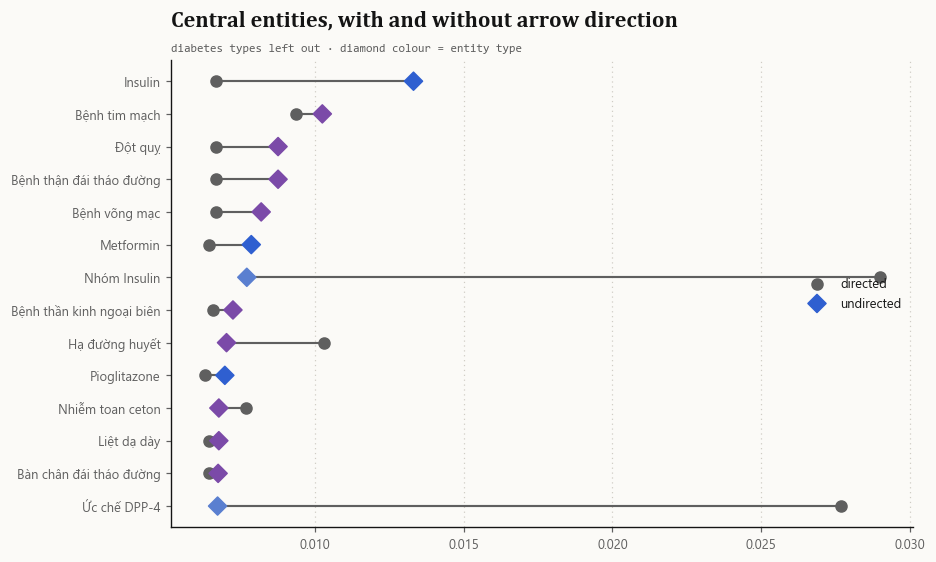

In [32]:
pr_dir = nx.pagerank(G, alpha=0.85)
pr_und = nx.pagerank(G.to_undirected(), alpha=0.85)
cent = pd.DataFrame({"type": nx.get_node_attributes(G, "type"), "degree": dict(G.degree()), "directed": pr_dir, "undirected": pr_und})
cent.index.name = "entity"
top = cent[cent.type != "DiabetesType"].sort_values("undirected", ascending=False).head(14)

rule("two PageRanks, two stories")
tbl(cent.sort_values("directed", ascending=False).head(5).round(4), "top 5 by directed PageRank (dead ends of the chains)", index=True)
tbl(cent.sort_values("undirected", ascending=False).head(5).round(4), "top 5 by undirected PageRank (central entities)", index=True)

fig, ax = plt.subplots(figsize=(8.6, 5.2))
y = np.arange(len(top))
ax.hlines(y, top.directed, top.undirected, color=INK_FAINT, lw=1.4)
ax.scatter(top.directed, y, marker="o", s=52, color=INK_FAINT, label="directed", zorder=3)
ax.scatter(top.undirected, y, marker="D", s=70, color=[TYPE_COLORS[t] for t in top.type], label="undirected", zorder=3)
ax.set_yticks(y, top.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.legend(loc="center right")
atlas.title(ax, "Central entities, with and without arrow direction", "diabetes types left out · diamond colour = entity type")
plt.tight_layout(); plt.show()

### 8.4 What Vinmec writes about most

A third kind of importance ignores the facts altogether. For each entity it counts the articles (out of 1,096) that mention it **anywhere**, via the `MENTIONS` links. This measures what the site *talks about*, which differs from how connected an entity is among facts. An entity can appear in many articles in passing, for example while explaining how blood sugar works, and still take part in few facts under a proper heading. Compare this chart with the PageRank one above to spot topics that are talked about a lot but rarely stated as a fact.

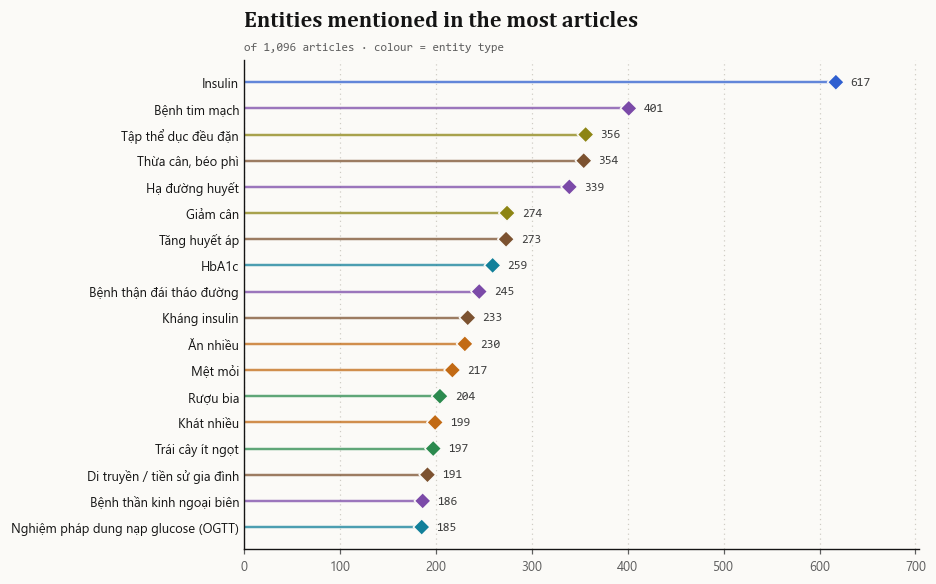

In [33]:
mc = cy("""
MATCH (a:Article)-[:MENTIONS]->(e:Entity)
RETURN [l IN labels(e) WHERE l <> 'Entity'][0] AS type, e.name AS entity, count(a) AS articles
ORDER BY articles DESC LIMIT 18""")
fig, ax = plt.subplots(figsize=(8.6, 5.4))
V.lollipop(ax, mc.entity, mc.articles.values, colors=[TYPE_COLORS[t] for t in mc.type])
atlas.title(ax, "Entities mentioned in the most articles", "of 1,096 articles · colour = entity type")
plt.tight_layout(); plt.show()

## 9 · How far to trust it

Every automatic extractor makes mistakes. The useful question is not *whether* but *how many, and of what kind*. Without measuring, no claim ("the graph says insulin causes X") can be trusted.

### What we measured

We measured **precision**: of the facts in the graph, what share are correct? The method:

1. draw 50 extracted facts **at random**, with a fixed seed so anyone re-running `kg/evaluate.py` gets the same 50;
2. for each, show a sentence from a section the extractor actually used, plus the article title;
3. judge each fact by reading **all** its supporting articles, not just the sentence shown.

"Correct" means the Vinmec articles really state this fact for this type of diabetes. It does **not** mean a doctor checked it against current clinical guidelines; that would be a different, far more expensive check.

Why random, and why only 50?

- **Random**, because hand-picked facts would unconsciously be the easy ones and flatter the result.
- **Fifty**, because each fact means reading several articles; 50 is enough to see the main error patterns and give a reasonable estimate.

### Result

**48 of 50 facts are correct: 96 %.** Both errors share one cause: a fact about a *complication* was attached to diabetes itself.

| wrong fact | what the articles really said |
|---|---|
| diabetes HAS_RISK_FACTOR high cholesterol | listed as a risk factor of the *kidney* and *eye* complications ("Những ai dễ bị bệnh thận đái tháo đường?") |
| diabetes HAS_SYMPTOM abdominal pain | a symptom of *ketoacidosis* and of nerve damage in the gut |

How precise is "96 %"? With 50 facts, the true value for the whole graph could be a bit higher or lower: another random 50 might hold one error or four. The standard calculation for this situation (the Wilson interval) says the true precision is very likely between **87 % and 99 %**. Read "96 %" as "roughly nine in ten or better", not as an exact number.


━━━ precision of the sample ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  correct              │ 48 / 50
  precision            │ 0.96
  95 % Wilson interval │ 0.87 – 0.99

▎by relation type
┌──────────────────┬─────────┬─────────┐
│ RELATION         │ SAMPLED │ CORRECT │
├──────────────────┼─────────┼─────────┤
│ AVOIDS_FOOD      │       7 │       7 │
│ DIAGNOSED_BY     │       6 │       6 │
│ HAS_COMPLICATION │       7 │       7 │
│ HAS_RISK_FACTOR  │      11 │      10 │
│ HAS_SYMPTOM      │       7 │       6 │
│ MANAGED_BY       │       2 │       2 │
│ RECOMMENDS_FOOD  │       3 │       3 │
│ TREATED_BY       │       7 │       7 │
└──────────────────┴─────────┴─────────┘
  8 rows

▎the wrong facts
┌────────────────┬─────────────────┬─────────────────┬──────────────────────────────────────────┐
│ SUBJECT        │ RELATION        │ OBJECT          │ ERROR_TYPE                               │
├────────────────┼─────────────────┼─────────────────┼──────────────────────

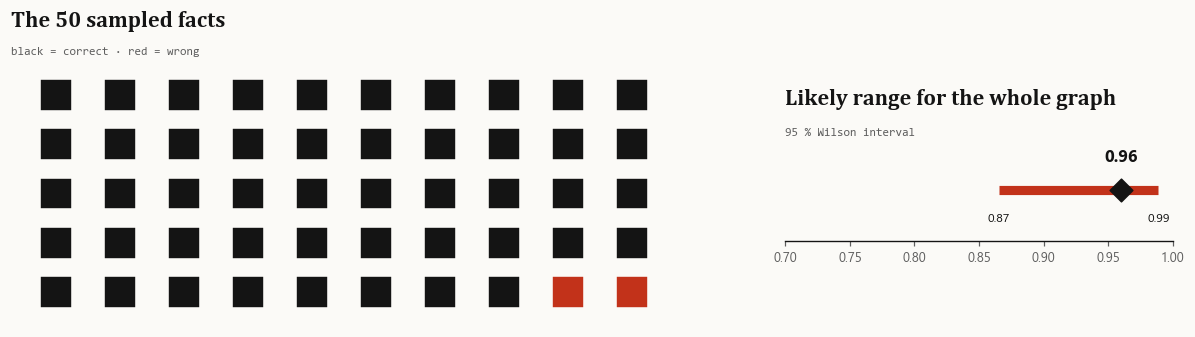

In [34]:
sample = pd.read_csv(ROOT / "evaluation" / "manual_audit.csv")
n, k = len(sample), int(sample.correct.sum())
z, p = 1.96, k / n
centre = (p + z * z / (2 * n)) / (1 + z * z / n)
half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
lo, hi = centre - half, centre + half

rule("precision of the sample")
kv({"correct": f"{k} / {n}", "precision": f"{p:.2f}", "95 % Wilson interval": f"{lo:.2f} – {hi:.2f}"})
by_rel = sample.groupby("relation").correct.agg(sampled="count", correct="sum").reset_index()
tbl(by_rel, "by relation type")
tbl(sample[sample.correct == 0][["subject", "relation", "object", "error_type"]], "the wrong facts", limit=40)

order = sample.sort_values("correct", ascending=False).reset_index(drop=True)
fig = plt.figure(figsize=(11, 3.1))
ax = fig.add_axes([0.02, 0.05, 0.55, 0.78]); ax.axis("off")
xs, ys = order.index % 10, order.index // 10
ax.scatter(xs, -ys, s=520, marker="s", color=[INK if c else ACCENT for c in order.correct], edgecolor=atlas.PAPER, lw=3)
ax.set_xlim(-0.7, 9.7); ax.set_ylim(-4.7, 0.7); atlas.title(ax, "The 50 sampled facts", "black = correct · red = wrong")
ax2 = fig.add_axes([0.66, 0.30, 0.32, 0.30]); ax2.set_xlim(0.7, 1.0); ax2.set_ylim(-1, 1); ax2.grid(False)
for s in ("left",):
    ax2.spines[s].set_visible(False)
ax2.set_yticks([]); ax2.hlines(0, lo, hi, color=ACCENT, lw=6); ax2.scatter([p], [0], marker="D", s=110, color=INK, zorder=3)
ax2.text(p, 0.55, f"{p:.2f}", ha="center", fontsize=11, fontweight="bold"); ax2.text(lo, -0.62, f"{lo:.2f}", ha="center", fontsize=8); ax2.text(hi, -0.62, f"{hi:.2f}", ha="center", fontsize=8)
atlas.title(ax2, "Likely range for the whole graph", "95 % Wilson interval")
plt.show()

### 9.1 Fixing the errors, and what the fix cost

The two errors led straight to the stricter heading rule of 3.3: symptom and risk-factor sections must be about diabetes itself, not about a complication or another disease. After the change the graph went from 345 to 339 facts. The six removed facts tell the story:

| removed fact | was removing it right? |
|---|---|
| type 1 HAS_SYMPTOM numb hands and feet | ✅ yes: that is the nerve-damage complication, not a symptom of type 1 |
| type 2 HAS_SYMPTOM sweating | ✅ yes: that is a symptom of low blood sugar |
| prediabetes HAS_RISK_FACTOR older age | ❌ no: a true fact lost |
| prediabetes HAS_RISK_FACTOR high blood pressure | ❌ no: a true fact lost |
| diabetes HAS_RISK_FACTOR long-term corticosteroid use | ❌ no: a true fact lost |
| type 2 HAS_RISK_FACTOR smoking | ❌ no: a true fact lost |

Why were four true facts lost? Each had exactly one good supporting article and one weak one. The stricter rule removed the weak one, support fell to 1, and the minimum of 2 deleted the fact.

And the two original errors? They **stayed**, with far less support (16 → 3 and 18 → 6 pages). Reading the remaining pages showed they *do* state these facts under genuine diabetes headings, for instance "Nguyên nhân và yếu tố nguy cơ gây bệnh tiểu đường: … Rối loạn mỡ máu". By our definition of correct (the articles state it) they are now properly supported.

This is the **precision / recall trade-off** every extraction system faces: strict rules give fewer wrong facts but miss more true ones; loose rules find more true facts and let in more wrong ones. No setting is best for every use, which is why support is kept on every fact instead of being used once as a filter. A chatbot giving health information might use only facts with support 3 or more; someone exploring the data can see everything. The chart shows how many extracted facts survive each level.


▎extracted facts left at each evidence level
┌─────────────┬────────────┬───────┐
│ MIN SUPPORT │ FACTS LEFT │ SHARE │
├─────────────┼────────────┼───────┤
│           1 │        301 │ 100 % │
│           2 │        295 │ 98 %  │
│           3 │        252 │ 84 %  │
│           5 │        161 │ 53 %  │
│          10 │         70 │ 23 %  │
│          20 │         32 │ 11 %  │
└─────────────┴────────────┴───────┘
  6 rows


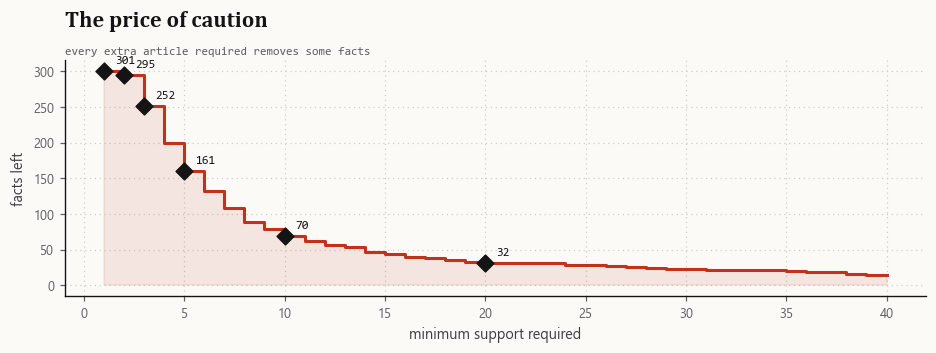

In [35]:
levels = [1, 2, 3, 5, 10, 20]
kept_n = [int(cy("MATCH ()-[r]->() WHERE r.source = 'vinmec' AND r.support >= $t RETURN count(r) AS n", t=t).n[0]) for t in levels]
total = kept_n[0]
tbl(pd.DataFrame({"min support": levels, "facts left": kept_n, "share": [f"{100 * n / total:.0f} %" for n in kept_n]}), "extracted facts left at each evidence level")

fig, ax = plt.subplots(figsize=(8.6, 3.3))
curve = [int((ext.support >= t).sum()) for t in range(1, 41)]
ax.step(range(1, 41), curve, where="post", color=ACCENT, lw=2); ax.fill_between(range(1, 41), curve, step="post", color=ACCENT, alpha=0.1)
ax.scatter(levels, kept_n, marker="D", s=60, color=INK, zorder=3)
for t, c in zip(levels, kept_n):
    ax.annotate(str(c), (t, c), textcoords="offset points", xytext=(7, 5), fontsize=8, fontfamily=atlas.MONO)
ax.set_xlabel("minimum support required"); ax.set_ylabel("facts left")
atlas.title(ax, "The price of caution", "every extra article required removes some facts")
plt.tight_layout(); plt.show()

## 10 · Blind spots

Following the lecture's list of ways a knowledge graph can fail, here is where this one does:

- **Missing entities.** The vocabulary is fixed: 106 entities written 320 ways. Anything absent can never be found, however much the articles discuss it (a newer insulin brand, a rarer complication, a traditional remedy). We measured precision, not **recall**, so we do not know how much is missing.
- **Wrong relationships.** About 4 % of the sampled facts were wrong, mostly a complication's fact attached to the disease. Headings are a strong signal of meaning, not a perfect one.
- **Ambiguous aliases.** Whole-word matching stops hits inside longer words but not short aliases that are complete words with another meaning: *táo* (fruit) also matches *táo bón* (constipation). The section rule makes it rare, not impossible.
- **Cause mistaken for side effect.** "Insulin HAS_SIDE_EFFECT ketoacidosis" survived the filter in 3.8. Ketoacidosis comes from a *lack* of insulin, phrased in ways the "thiếu / không đủ" check misses.
- **Coarse subjects.** The type is read from the title only, so many type 2 facts sit on the general node.
- **Fixed food advice.** Recommended or avoid is decided by the food, not read from the article, so "fruit is fine in moderation" is lost.
- **Merged or split meanings.** Aliases merge near-synonyms ("tê bì", "dị cảm", "kiến bò" become one node), sometimes merging what a doctor would separate.
- **One source, many ages.** Everything comes from one hospital's site, and an article from 2019 counts like one from 2025. "Correct" means "stated by Vinmec", not "checked against current guidelines".
- **Hand-added facts.** Drug classes, organs and thresholds were written by hand. They are labelled `curated`, but they were not learned from the articles.
- **Not medical advice.** The graph summarises public health articles. The symptom finder shows which types the articles associate with symptoms; it diagnoses nobody.

In [36]:
driver.close()
rule("done")
print("  Neo4j connection closed. Every figure above was drawn from the same CSV files and database as the website.")


━━━ done ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Neo4j connection closed. Every figure above was drawn from the same CSV files and database as the website.
